# Summary
**Goal**  
This project investigates delay patterns and network dynamics across Germany's major railway stations to understand operational efficiency, connectivity hierarchies, and temporal performance variations. By analyzing six days of real-time delay data from 20 key stations, the study addresses five interconnected research questions about how the Deutsche Bahn network operates.

**Research Questions**  
1. **RQ1: Station Delay Management Efficiency** – Which stations effectively reduce delays versus which ones add additional delays during stops? (Examines turnaround operations and schedule buffers)  
2. **RQ2: Station Connectivity & Hub Identification** – How interconnected are Germany's major train hubs, and what is their strategic importance? (Identifies critical network nodes)  
3. **RQ3: Train Type Specialization by Station** – Do certain stations specialize in specific train types (ICE, IC, EC), and what does this reveal about their role in the network?  
4. **RQ4: Most Important Rail Corridors** – What are the most critical train corridors, and do they show balanced bidirectional traffic or directional imbalances?  
5. **RQ5: Peak Hour Performance Analysis** – Do train delays increase during peak hours, indicating network congestion and operational bottlenecks?

**Methodology**  
ELT (Extract, Load, Transform) approach using Python and MongoDB to:  
- Extract delay data from the DB OpenData API (20 stations, six days of data)  
- Load raw data into MongoDB collections  
- Transform data through sophisticated aggregation pipelines (10+ stages)  
- Analyze results across five complementary research dimensions

**Key Findings**  
- Mannheim Hbf emerges as the most efficient delay-recovery station (-1.0 min average change)  
- Frankfurt Hbf, München Hbf, and Stuttgart Hbf are the most connected hubs (203, 187, 186 unique connections respectively)  
- Strong ICE specialization at major hubs; more balanced IC/EC mix at regional stations  
- Stable bidirectional corridors (Karlsruhe ↔ Leipzig) contrast with asymmetric end-of-line flows (Berlin → Berlin Ostbahnhof)  
- Evening peak (16:00–19:00) drives highest delays; cascading delays persist into late night despite reduced traffic

<div style="page-break-before: always;"></div>

# Requirements & Configuration
This section outlines the necessary software, libraries, and configuration steps required to
reproduce the analysis presented in this notebook.

## Software & Libraries
This analysis was developed in a Python environment (Python 3.8+ is recommended). To ensure
reproducibility, all required external Python libraries are listed below. These libraries handle
tasks such as making API requests, connecting to the MongoDB Atlas database, and securely
managing environment variables.

In [34]:
import os
import json
import time
import requests
import xml.etree.ElementTree as ET
import pandas as pd
import folium
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from typing import Dict, List, Optional
from pymongo import MongoClient
from pymongo.server_api import ServerApi
from dotenv import load_dotenv
from pprint import pprint
from matplotlib import cm
from matplotlib.colors import Normalize

## Station Configuration

This analysis focuses on 20 major German railway stations representing key hubs across the country's primary railway corridors. The stations were selected to provide comprehensive geographic coverage and include the most critical network nodes. These stations span from northern cities like Hamburg and Bremen to southern hubs such as München and Augsburg, and from western centers like Köln to eastern terminals including Berlin and Dresden.

Each station is identified by its official Deutsche Bahn EVA (Elektronische Verwaltung Abfahrts- und Ankunftszeiten) code, which serves as the unique identifier for API queries. The geographic distribution of these stations enables analysis of delay patterns, connectivity hierarchies, and operational efficiency across Germany's interconnected railway network.


In [29]:
# ============================================================================
# SECTION 3: STATION CONFIGURATION
# ============================================================================
# Major German railway stations for analysis

STATIONS = {
    "Hamburg Hbf": "8002549",
    "Bremen Hbf": "8000050",
    "Hannover Hbf": "8000152",
    "Berlin Hbf": "8011160",
    "Leipzig Hbf": "8010205",
    "Dresden Hbf": "8010085",
    "Erfurt Hbf": "8010101",
    "Köln Hbf": "8000207",
    "Düsseldorf Hbf": "8000085",
    "Dortmund Hbf": "8000080",
    "Essen Hbf": "8000098",
    "Frankfurt Hbf": "8000105",
    "Mannheim Hbf": "8000244",
    "Kassel-Wilhelmshöhe": "8000199",
    "München Hbf": "8000261",
    "Stuttgart Hbf": "8000096",
    "Nürnberg Hbf": "8000284",
    "Karlsruhe Hbf": "8000191",
    "Würzburg Hbf": "8000260",
    "Augsburg Hbf": "8000013"
}

# Group by region (rough geographic grouping)
regions = {
    "North": ["Hamburg Hbf", "Bremen Hbf", "Hannover Hbf"],
    "East": ["Berlin Hbf", "Leipzig Hbf", "Dresden Hbf", "Erfurt Hbf"],
    "West": ["Köln Hbf", "Düsseldorf Hbf", "Dortmund Hbf", "Essen Hbf"],
    "Central": ["Frankfurt Hbf", "Mannheim Hbf", "Kassel-Wilhelmshöhe"],
    "South": ["München Hbf", "Stuttgart Hbf", "Nürnberg Hbf", "Karlsruhe Hbf", 
              "Würzburg Hbf", "Augsburg Hbf"]
}

## Environment Configuration

**Credentials Notice**  
To successfully run this notebook, credentials for both the MongoDB Atlas database and the Deutsche Bahn (DB) API are required. These sensitive credentials have been securely stored in a `.env` file in the project's root directory and are not included in this distribution.

**For Reproducibility**  
To reproduce this analysis, register your own application for the Timetables API on the DB API Marketplace and set up a MongoDB Atlas cluster; see the README for details.

**Required Environment Variables**  
The notebook expects the following environment variables to be available:  
- `MONGODB_URI` – MongoDB Atlas connection string  
- `DB_CLIENT_ID` – Deutsche Bahn API client ID  
- `DB_API_KEY` – Deutsche Bahn API key


In [26]:
#| echo: fenced
#| code-overflow: wrap
# ============================================================================
# ENVIRONMENT SETUP
# ============================================================================

# Load environment variables
load_dotenv()

# Configuration and Validation
MONGODB_URI = os.getenv('MONGODB_URI')
DB_CLIENT_ID = os.getenv('DB_CLIENT_ID')
DB_API_KEY = os.getenv('DB_API_KEY')

# Validate that all required environment variables are set
if not all([MONGODB_URI, DB_CLIENT_ID, DB_API_KEY]):
     raise ValueError(
         "ERROR: Missing environment variables. "
         "Ensure MONGODB_URI, DB_CLIENT_ID, and DB_API_KEY are set in your .env file."
     )
print("Environment variables loaded successfully.")
 
# MongoDB Connection
try:
    client = MongoClient(MONGODB_URI, server_api=ServerApi('1'), serverSelectionTimeoutMS=5000)
    client.admin.command('ping') # Test connection
    db = client['bahn_analysis']
    print(f"MongoDB Atlas connected successfully to database: '{db.name}'")
except Exception as e:
    print(f"FATAL: MongoDB connection failed. Please check your MONGODB_URI and network  access.")
    raise e

Environment variables loaded successfully.
MongoDB Atlas connected successfully to database: 'bahn_analysis'


# ELT Process

## DB Setup
The database setup phase establishes the foundational MongoDB infrastructure required to support the ELT pipeline. Three primary collections are created to segregate raw data by function: `raw_timetable_plan` stores scheduled train timetables extracted from the Deutsche Bahn Plan API,
maintaining planned departure and arrival times with associated platform information; `raw_timetable_changes` captures real-time operational data including actual times, delays, cancellations, and platform changes from the Changes API; and `collection_log` serves as an audit trail, documenting all collection runs with metadata including duration, station coverage, and aggregated record counts. To optimize query performance and maintain data integrity, strategic
indexes are implemented on each collection. The `raw_timetable_plan` collection features a composite
unique index on (`station.eva`, `date`, `hour`) to prevent duplicate hourly timetable entries,
supplemented by a descending index on `collection_timestamp` for efficient time-series queries. The
`raw_timetable_changes` collection indexes on (`station.eva`, `collection_timestamp`) to enable rapid
retrieval of changes by station and collection time. The `collection_log` collection maintains a
reverse chronological index on `collection_start` for quick access to recent collection runs. This
schema design reflects the pipeline's architecture: the separation of plan and changes data enables
independent extraction from their respective APIs while maintaining referential integrity through the `journey_id` field, which is subsequently used in the [Transform stage](#transform) (Section 3.4) to correlate planned and actual times via MongoDB's `$lookup` aggregation operator. Upon initialization, the setup script displays the current document counts across all three collections, providing immediate validation that the collections are active and ready to receive data from the Extract phase.

In [5]:
# ============================================================================
# 3.1 DB Setup
# ============================================================================
# This section initializes the MongoDB collections used for storing raw data
# from the Deutsche Bahn APIs. It also ensures that necessary indexes are
# created to optimize data retrieval and prevent duplicate entries.

print("=" * 70)
print("DATABASE COLLECTIONS SETUP")
print("=" * 70)
print()

# Collection 1: Raw Plan Data
print("Setting up raw_timetable_plan collection...")

# Create unique index to prevent duplicate collection
db.raw_timetable_plan.create_index([
    ('station.eva', 1),
    ('date', 1),
    ('hour', 1)
], unique=True, name='station_date_hour_unique')

db.raw_timetable_plan.create_index([
    ('collection_timestamp', -1)
], name='collection_timestamp_desc')

print("raw_timetable_plan indexes created")

# Collection 2: Raw Changes Data
print("Setting up raw_timetable_changes collection...")

db.raw_timetable_changes.create_index([
    ('station.eva', 1),
    ('collection_timestamp', -1)
], name='station_timestamp')

print("raw_timetable_changes indexes created")

# Collection 3: Collection Log
print("Setting up collection_log collection...")

db.collection_log.create_index([
    ('collection_start', -1)
], name='collection_start_desc')

print("collection_log indexes created")

print()
print("-" * 70)
print()

# Show current collections status
print("Current database status:")
print()

for coll_name in ['raw_timetable_plan', 'raw_timetable_changes', 'collection_log']:
    count = db[coll_name].count_documents({})
    print(f"  {coll_name}: {count:,} documents")


DATABASE COLLECTIONS SETUP

Setting up raw_timetable_plan collection...
raw_timetable_plan indexes created
Setting up raw_timetable_changes collection...
raw_timetable_changes indexes created
Setting up collection_log collection...
collection_log indexes created

----------------------------------------------------------------------

Current database status:

  raw_timetable_plan: 1,920 documents
  raw_timetable_changes: 141 documents
  collection_log: 7 documents


Collections ready for raw data storage!



## Extract
The Extract phase implements a multi-layered architecture for systematically acquiring and
processing raw data from the Deutsche Bahn timetable APIs. The extraction process operates on two
parallel data streams: the [Plan API Function](#plan-api-functions) (Section 3.2.1) retrieves scheduled timetable information for
specified station-hour combinations, providing planned departure and arrival times with platform
assignments; the [Changes API Function](#changes-api-functions) (Section 3.2.2) captures real-time operational updates including
actual times, delays, cancellations, and dynamic platform changes across all recent journeys at a
station, regardless of hour boundaries. Both APIs return responses in XML format, necessitating a
[robust parsing layer](#xml-parsing-functions) (Section 3.2.3) that converts unstructured XML into normalized, type-safe
Python dictionaries. The parsing functions handle two distinct data transformations:
`parse_plan_xml()` extracts scheduled train information filtered to long-distance services
(Fernverkehr: ICE, IC, EC), structuring each train's journey metadata, planned times, and platform
information; `parse_changes_xml()` processes real-time data by extracting actual times (ct
attribute), calculating delay_minutes by comparing actual versus planned times, and flagging
cancelled journeys. To operationalize these capabilities, the [Data Collection Orchestration
Functions](#data-collection-orchestration-functions) (Section 3.2.4) provide three levels of abstraction: `collect_station_hour_raw()` handles
single station-hour extraction and storage, serving as the atomic building block;
`collect_station_day_raw()` iterates across all 24 hours for a single station and date, collecting
plan data hourly while fetching changes data once per station per day (reflecting API design where
changes are station-level, not hour-specific); and `collect_days_raw()` orchestrates multi-day,
multi-station collection campaigns with flexible date ranges and station selections, automatically
calculating rate-limiting delays and logging all collection metadata to the `collection_log` for
audit and monitoring purposes. This hierarchical design enables both granular control for targeted
extractions and automated batch processing for continuous data pipeline operations.

### Plan API Functions

In [31]:
# ============================================================================
# 3.2.1 PLAN API FUNCTIONS
# ============================================================================
# Functions to fetch scheduled timetable data

def fetch_timetable(station_eva: str, date: str, hour: str) -> Dict:
    """
    Fetch planned timetable for a specific station, date, and hour.
    
    This API returns the PLANNED schedule (pt = planned time).
    
    Parameters:
    -----------
    station_eva : str
        EVA station number
    date : str
        Date in format YYMMDD (e.g., '251015')
    hour : str
        Hour in format HH (e.g., '14')
        
    Returns:
    --------
    dict : API response with status, data, and metadata
    """
    base_url = "https://apis.deutschebahn.com/db-api-marketplace/apis/timetables/v1"
    url = f"{base_url}/plan/{station_eva}/{date}/{hour}"
    
    headers = {
        'DB-Client-Id': DB_CLIENT_ID,
        'DB-Api-Key': DB_API_KEY,
        'accept': 'application/xml'
    }
    
    try:
        response = requests.get(url, headers=headers, timeout=10)
        
        return {
            'status_code': response.status_code,
            'success': response.status_code == 200,
            'data': response.text if response.status_code == 200 else None,
            'error': None if response.status_code == 200 else response.text,
            'url': url,
            'station_eva': station_eva,
            'date': date,
            'hour': hour
        }
        
    except requests.exceptions.Timeout:
        return {
            'status_code': None,
            'success': False,
            'data': None,
            'error': 'Request timeout',
            'url': url,
            'station_eva': station_eva,
            'date': date,
            'hour': hour
        }
    except Exception as e:
        return {
            'status_code': None,
            'success': False,
            'data': None,
            'error': str(e),
            'url': url,
            'station_eva': station_eva,
            'date': date,
            'hour': hour
        }


# Test Plan API
print("=" * 70)
print("PLAN API TEST")
print("=" * 70)
print()

test_date = datetime.now().strftime("%y%m%d")
test_hour = datetime.now().strftime("%H")

print(f"Testing Plan API:")
print(f"  Station: Frankfurt Hbf (8000105)")
print(f"  Date: {test_date}")
print(f"  Hour: {test_hour}")
print()

result = fetch_timetable("8000105", test_date, test_hour)

if result['success']:
    print("Plan API works!")
    print(f"   Response length: {len(result['data'])} chars")
    print()
    pprint("Sample XML (first 500 chars):")
    print(result['data'][:500])
else:
    print(f"Plan API failed: {result['error']}")

print()
print("=" * 70)

PLAN API TEST

Testing Plan API:
  Station: Frankfurt Hbf (8000105)
  Date: 251106
  Hour: 12

Plan API failed: <?xml version="1.0" encoding="UTF-8"?>
<errorResponse>
  <httpCode>401</httpCode>
  <httpMessage>Unauthorized</httpMessage>
  <moreInformation>Invalid client id or secret.</moreInformation>
</errorResponse>



### Changes API Functions

In [7]:
# ============================================================================
# 3.2.2 CHANGES API FUNCTIONS
# ============================================================================
# Functions to fetch real-time changes (delays, cancellations)

def fetch_changes(station_eva: str) -> Dict:
    """
    Fetch recent changes/delays for a station.
    
    This API returns ACTUAL times and delays (ct = changed time).
    Returns all recent changes, not limited to a specific hour.
    
    Parameters:
    -----------
    station_eva : str
        EVA station number
        
    Returns:
    --------
    dict : API response with status, data, and metadata
    """
    base_url = "https://apis.deutschebahn.com/db-api-marketplace/apis/timetables/v1"
    url = f"{base_url}/fchg/{station_eva}"
    
    headers = {
        'DB-Client-Id': DB_CLIENT_ID,
        'DB-Api-Key': DB_API_KEY,
        'accept': 'application/xml'
    }
    
    try:
        response = requests.get(url, headers=headers, timeout=10)
        
        return {
            'status_code': response.status_code,
            'success': response.status_code == 200,
            'data': response.text if response.status_code == 200 else None,
            'error': None if response.status_code == 200 else response.text,
            'url': url,
            'station_eva': station_eva
        }
        
    except requests.exceptions.Timeout:
        return {
            'status_code': None,
            'success': False,
            'data': None,
            'error': 'Request timeout',
            'url': url,
            'station_eva': station_eva
        }
    except Exception as e:
        return {
            'status_code': None,
            'success': False,
            'data': None,
            'error': str(e),
            'url': url,
            'station_eva': station_eva
        }


# Test Changes API
print("=" * 70)
print("CHANGES API TEST")
print("=" * 70)
print()

print(f"Testing Changes API:")
print(f"  Station: Frankfurt Hbf (8000105)")
print()

result = fetch_changes("8000105")

if result['success']:
    print("Changes API works!")
    print(f"   Response length: {len(result['data'])} chars")
    
    # Check if ct (changed time) is present
    if 'ct=' in result['data']:
        ct_count = result['data'].count('ct=')
        print(f"   Found {ct_count} 'ct' (changed time) attributes!")
        print("   → Actual times and delays are available!")
    else:
        print("   No 'ct' attributes found")
        print("   → May need to wait for trains to depart")
    
    print()
    print("Sample XML (first 800 chars):")
    print(result['data'][:800])
else:
    print(f"Changes API failed: {result['error']}")

print()
print("=" * 70)

CHANGES API TEST

Testing Changes API:
  Station: Frankfurt Hbf (8000105)

Changes API works!
   Response length: 257021 chars
   Found 580 'ct' (changed time) attributes!
   → Actual times and delays are available!

Sample XML (first 800 chars):
<timetable station="Frankfurt(Main)Hbf" eva="8000105">

<s id="7945632340812070418-2511060838-21" eva="8000105">
    <ar ct="2511061033" l="RB82"/>
</s>


<s id="1865596122014212731-2511060925-1" eva="8000105">
    <dp ct="2511060928" l="RB82"/>
</s>


<s id="6457603581741321123-2511060555-10" eva="8000105">
    <m id="r2517364" t="h" from="2511021845" to="2511112359" cat="Störung" ts="2511021917" ts-tts="25-11-05 23:16:04.470" pr="1"/>
    <m id="r1126602576alt" t="c" ts="2511060909" ts-tts="25-11-06 09:09:22.924"/>
    <m id="r1126602550alt" t="c" ts="2511060907" ts-tts="25-11-06 09:07:16.823"/>
    <m id="r1126602404alt" t="c" ts="2511060857" ts-tts="25-11-06 08:57:49.483"/>
    <m id="r1126602402alt" t="c" ts="2511060857" ts-tts="25-11-06 

### XML Parsing Functions

In [8]:
# ============================================================================
# 3.2.3 XML PARSING FUNCTIONS
# ============================================================================
# Parse XML responses from Plan and Changes APIs

def parse_db_time(time_str: str) -> Optional[datetime]:
    """
    Parse Deutsche Bahn time string to datetime.
    
    Format: YYMMDDhhmm (e.g., '2510151430' = 2025-10-15 14:30)
    
    Parameters:
    -----------
    time_str : str
        Time string in DB format
        
    Returns:
    --------
    datetime or None
    """
    if not time_str or len(time_str) != 10:
        return None
    
    try:
        year = 2000 + int(time_str[0:2])
        month = int(time_str[2:4])
        day = int(time_str[4:6])
        hour = int(time_str[6:8])
        minute = int(time_str[8:10])
        
        return datetime(year, month, day, hour, minute)
    except:
        return None


def parse_plan_xml(xml_data: str, station_name: str, station_eva: str) -> List[Dict]:
    """
    Parse Plan API XML to extract scheduled train data.
    
    Returns trains with PLANNED times (pt attribute).
    
    Parameters:
    -----------
    xml_data : str
        XML response from Plan API
    station_name : str
        Name of the station
    station_eva : str
        EVA number of station
        
    Returns:
    --------
    list : List of train dictionaries with planned times
    """
    if not xml_data:
        return []
    
    try:
        root = ET.fromstring(xml_data)
    except Exception as e:
        print(f"XML parsing error: {e}")
        return []
    
    trains = []
    
    # Iterate through all train elements
    for train_elem in root.findall('.//s'):
        journey_id = train_elem.get('id')
        
        if not journey_id:
            continue
        
        # Get train info from tl (train line) element
        tl_elem = train_elem.find('tl')
        if tl_elem is None:
            continue
        
        train_type = tl_elem.get('c', '')  # Category (ICE, IC, etc.)
        train_number = tl_elem.get('n', '')  # Number
        
        # Filter: Only Fernverkehr (long-distance)
        if train_type not in ['ICE', 'IC', 'EC']:
            continue
        
        train = {
            'journey_id': journey_id,
            'station': {
                'name': station_name,
                'eva': station_eva
            },
            'train': {
                'type': train_type,
                'number': train_number,
                'line': tl_elem.get('o', ''),  # Owner/Operator
            },
            'departure': None,
            'arrival': None
        }
        
        # Parse departure (dp element)
        dp_elem = train_elem.find('dp')
        if dp_elem is not None:
            train['departure'] = {
                'planned_time_raw': dp_elem.get('pt'),
                'planned_time': parse_db_time(dp_elem.get('pt')),
                'platform_planned': dp_elem.get('pp'),
                'path': dp_elem.get('ppth', ''),  # Platform path
                'line': dp_elem.get('l', '')
            }
        
        # Parse arrival (ar element)
        ar_elem = train_elem.find('ar')
        if ar_elem is not None:
            train['arrival'] = {
                'planned_time_raw': ar_elem.get('pt'),
                'planned_time': parse_db_time(ar_elem.get('pt')),
                'platform_planned': ar_elem.get('pp'),
                'path': ar_elem.get('ppth', ''),
                'line': ar_elem.get('l', '')
            }
        
        trains.append(train)
    
    return trains


def parse_changes_xml(xml_data: str, station_eva: str) -> List[Dict]:
    """
    Parse Changes API XML to extract actual times and delays.
    
    Returns trains with ACTUAL times (ct attribute) and delays.
    
    Parameters:
    -----------
    xml_data : str
        XML response from Changes API
    station_eva : str
        EVA number of station
        
    Returns:
    --------
    list : List of change dictionaries with actual times
    """
    if not xml_data:
        return []
    
    try:
        root = ET.fromstring(xml_data)
    except Exception as e:
        print(f"XML parsing error: {e}")
        return []
    
    changes = []
    
    # Iterate through all train elements
    for train_elem in root.findall('.//s'):
        journey_id = train_elem.get('id')
        
        if not journey_id:
            continue
        
        change = {
            'journey_id': journey_id,
            'station_eva': station_eva,
            'departure': {},
            'arrival': {},
            'is_cancelled': False
        }
        
        # Check if train is cancelled
        tl_elem = train_elem.find('tl')
        if tl_elem is not None:
            change['is_cancelled'] = tl_elem.get('f') == 'c'  # f="c" means cancelled
        
        # Parse departure changes
        dp_elem = train_elem.find('dp')
        if dp_elem is not None:
            planned_raw = dp_elem.get('pt')
            actual_raw = dp_elem.get('ct')
            
            change['departure'] = {
                'planned_time_raw': planned_raw,
                'planned_time': parse_db_time(planned_raw),
                'actual_time_raw': actual_raw,
                'actual_time': parse_db_time(actual_raw),
                'platform_planned': dp_elem.get('pp'),
                'platform_actual': dp_elem.get('cp'),  # Changed platform
                'status': dp_elem.get('cs')  # Cancellation status
            }
            
            # Calculate delay
            if actual_raw and planned_raw:
                planned_dt = parse_db_time(planned_raw)
                actual_dt = parse_db_time(actual_raw)
                if planned_dt and actual_dt:
                    delay = (actual_dt - planned_dt).total_seconds() / 60
                    change['departure']['delay_minutes'] = int(delay)
        
        # Parse arrival changes
        ar_elem = train_elem.find('ar')
        if ar_elem is not None:
            planned_raw = ar_elem.get('pt')
            actual_raw = ar_elem.get('ct')
            
            change['arrival'] = {
                'planned_time_raw': planned_raw,
                'planned_time': parse_db_time(planned_raw),
                'actual_time_raw': actual_raw,
                'actual_time': parse_db_time(actual_raw),
                'platform_planned': ar_elem.get('pp'),
                'platform_actual': ar_elem.get('cp'),
                'status': ar_elem.get('cs')
            }
            
            # Calculate delay
            if actual_raw and planned_raw:
                planned_dt = parse_db_time(planned_raw)
                actual_dt = parse_db_time(actual_raw)
                if planned_dt and actual_dt:
                    delay = (actual_dt - planned_dt).total_seconds() / 60
                    change['arrival']['delay_minutes'] = int(delay)
        
        # Only add if there are actual changes (ct present)
        if (change['departure'].get('actual_time_raw') or 
            change['arrival'].get('actual_time_raw') or 
            change['is_cancelled']):
            changes.append(change)
    
    return changes


# Test parsing functions
print("=" * 70)
print("PARSING FUNCTIONS TEST")
print("=" * 70)
print()

# Test with Plan data
print("Testing Plan XML parsing...")
plan_result = fetch_timetable("8000105", datetime.now().strftime("%y%m%d"), 
                              datetime.now().strftime("%H"))

if plan_result['success']:
    trains = parse_plan_xml(plan_result['data'], "Frankfurt Hbf", "8000105")
    print(f"Parsed {len(trains)} Fernverkehr trains from Plan API")
    
    if trains:
        print()
        print("Sample train (planned data):")
        sample = trains[0]
        print(f"  Journey ID: {sample['journey_id']}")
        print(f"  Train: {sample['train']['type']} {sample['train']['number']}")
        if sample['departure']:
            print(f"  Departure planned: {sample['departure']['planned_time']}")
        if sample['arrival']:
            print(f"  Arrival planned: {sample['arrival']['planned_time']}")

print()
print("-" * 70)
print()

# Test with Changes data
print("Testing Changes XML parsing...")
changes_result = fetch_changes("8000105")

if changes_result['success']:
    changes = parse_changes_xml(changes_result['data'], "8000105")
    print(f"Parsed {len(changes)} changes from Changes API")
    
    # Count changes with actual times
    with_ct = sum(1 for c in changes 
                  if c['departure'].get('actual_time_raw') or 
                     c['arrival'].get('actual_time_raw'))
    
    print(f"   Changes with actual times (ct): {with_ct}")
    
    if with_ct > 0:
        # Find first change with delay
        for change in changes:
            if change['departure'].get('delay_minutes') is not None:
                print()
                print("Sample change (with delay):")
                print(f"  Journey ID: {change['journey_id']}")
                print(f"  Departure planned: {change['departure']['planned_time']}")
                print(f"  Departure actual: {change['departure']['actual_time']}")
                print(f"  Delay: {change['departure']['delay_minutes']} minutes")
                break

print()
print("=" * 70)

PARSING FUNCTIONS TEST

Testing Plan XML parsing...
Parsed 15 Fernverkehr trains from Plan API

Sample train (planned data):
  Journey ID: -2525250539796034766-2511060557-10
  Train: ICE 1573
  Departure planned: 2025-11-06 09:19:00
  Arrival planned: 2025-11-06 09:08:00

----------------------------------------------------------------------

Testing Changes XML parsing...
Parsed 501 changes from Changes API
   Changes with actual times (ct): 501

Sample change (with delay):
  Journey ID: 8877134481212521389-2511060416-12
  Departure planned: 2025-11-06 08:50:00
  Departure actual: 2025-11-06 09:49:00
  Delay: 59 minutes



### Data Collection Orchestration Functions

In [10]:
# ============================================================================
# 3.2.4 Data Collection Orchestration Functions
# ============================================================================
# Functions to collect and store raw data from both APIs

def collect_station_hour_raw(station_name: str, station_eva: str, 
                             date: str, hour: str) -> Dict:
    """
    Collect raw data from BOTH Plan and Changes APIs for one station-hour.
    
    Stores data in separate raw collections without merging.
    
    Parameters:
    -----------
    station_name : str
        Name of the station
    station_eva : str
        EVA number
    date : str
        Date in YYMMDD format
    hour : str
        Hour in HH format
        
    Returns:
    --------
    dict : Collection results with counts
    """
    result = {
        'station': station_name,
        'eva': station_eva,
        'date': date,
        'hour': hour,
        'plan_success': False,
        'changes_success': False,
        'plan_trains': 0,
        'changes_count': 0,
        'error': None
    }
    
    collection_timestamp = datetime.now()
    
    # 1. Fetch and store PLAN data
    try:
        plan_result = fetch_timetable(station_eva, date, hour)
        
        if plan_result['success']:
            # Parse trains
            trains = parse_plan_xml(plan_result['data'], station_name, station_eva)
            
            if trains:
                # Store in raw_timetable_plan
                plan_doc = {
                    'station': {
                        'name': station_name,
                        'eva': station_eva
                    },
                    'date': date,
                    'hour': hour,
                    'collection_timestamp': collection_timestamp,
                    'trains': trains,
                    'train_count': len(trains)
                }
                
                # Use replace_one with upsert to avoid duplicates
                db.raw_timetable_plan.replace_one(
                    {
                        'station.eva': station_eva,
                        'date': date,
                        'hour': hour
                    },
                    plan_doc,
                    upsert=True
                )
                
                result['plan_success'] = True
                result['plan_trains'] = len(trains)
        else:
            result['error'] = plan_result.get('error', 'Unknown error')
            
    except Exception as e:
        result['error'] = f"Plan API error: {str(e)}"
    
    # 2. Fetch and store CHANGES data
    try:
        changes_result = fetch_changes(station_eva)
        
        if changes_result['success']:
            # Parse changes
            changes = parse_changes_xml(changes_result['data'], station_eva)
            
            # Store in raw_timetable_changes
            changes_doc = {
                'station': {
                    'name': station_name,
                    'eva': station_eva
                },
                'collection_timestamp': collection_timestamp,
                'changes': changes,
                'changes_count': len(changes)
            }
            
            db.raw_timetable_changes.insert_one(changes_doc)
            
            result['changes_success'] = True
            result['changes_count'] = len(changes)
            
    except Exception as e:
        if not result['error']:
            result['error'] = f"Changes API error: {str(e)}"
    
    # Small delay to respect rate limits
    time.sleep(1)
    
    return result


def collect_station_day_raw(station_name: str, station_eva: str, 
                            date: str, hours_list: List[str] = None) -> Dict:
    """
    Collect raw data for one station for all hours of a day.
    
    Parameters:
    -----------
    station_name : str
        Name of the station
    station_eva : str
        EVA number
    date : str
        Date in YYMMDD format
    hours_list : list, optional
        List of hours to collect (default: all 24)
        
    Returns:
    --------
    dict : Collection summary
    """
    if hours_list is None:
        hours_list = [f"{h:02d}" for h in range(24)]
    
    print(f"Collecting data for {station_name} on {date}")
    print(f"Hours: {len(hours_list)} hours")
    print()
    
    total_trains = 0
    hours_collected = 0
    
    # 1. COLLECT PLAN DATA for each hour
    for hour in hours_list:
        result = fetch_timetable(station_eva, date, hour)
        
        if result['success']:
            # Parse trains
            trains = parse_plan_xml(result['data'], station_name, station_eva)
            
            if trains:
                # Store in raw_timetable_plan
                plan_doc = {
                    'station': {
                        'name': station_name,
                        'eva': station_eva
                    },
                    'date': date,
                    'hour': hour,
                    'collection_timestamp': datetime.now(),
                    'trains': trains,
                    'train_count': len(trains)
                }
                
                # Use replace_one with upsert to avoid duplicates
                db.raw_timetable_plan.replace_one(
                    {
                        'station.eva': station_eva,
                        'date': date,
                        'hour': hour
                    },
                    plan_doc,
                    upsert=True
                )
                
                hours_collected += 1
                total_trains += len(trains)
                
                print(f"  Hour {hour}: {len(trains)} trains")
            else:
                print(f"  Hour {hour}: 0 trains")
        else:
            print(f"  Hour {hour}: ERROR - {result.get('error', 'Unknown')}")
        
        time.sleep(1)  # Rate limiting
    
    # 2. COLLECT CHANGES DATA - ONCE per station per day!
    print()
    print("  Collecting changes (once per station)...")
    
    changes_result = fetch_changes(station_eva)
    changes_count = 0
    
    if changes_result['success']:
        # Parse changes
        changes = parse_changes_xml(changes_result['data'], station_eva)
        
        if changes:
            # Store in raw_timetable_changes - ONCE!
            changes_doc = {
                'station': {
                    'name': station_name,
                    'eva': station_eva
                },
                'date': date,
                'collection_timestamp': datetime.now(),
                'changes': changes,
                'changes_count': len(changes)
            }
            
            db.raw_timetable_changes.insert_one(changes_doc)
            changes_count = len(changes)
            
            print(f"  Changes: {changes_count} unique changes")
        else:
            print(f"  Changes: 0 changes")
    else:
        print(f"  Changes: ERROR - {changes_result.get('error', 'Unknown')}")
    
    print()
    print(f"Summary for {station_name}:")
    print(f"  Total hours collected: {hours_collected}/{len(hours_list)}")
    print(f"  Total trains: {total_trains}")
    print(f"  Total changes: {changes_count}")
    print()
    
    return {
        'station': station_name,
        'eva': station_eva,
        'date': date,
        'hours_collected': hours_collected,
        'total_hours': len(hours_list),
        'total_trains': total_trains,
        'total_changes': changes_count
    }


def collect_days_raw(start_date: datetime = None, days: int = 1, 
                     stations_dict: Dict = None, 
                     hours_per_day: List[str] = None) -> Dict:
    """
    Collect raw data for multiple stations over multiple days.
    
    Flexible function that can collect 1 day or multiple days.
    
    Parameters:
    -----------
    start_date : datetime, optional
        Start date (default: today)
    days : int, optional
        Number of days to collect (default: 1 for daily collection)
    stations_dict : dict, optional
        Stations to collect (default: all STATIONS)
    hours_per_day : list, optional
        Hours to collect per day (default: all 24)
        
    Returns:
    --------
    dict : Complete collection summary
    """
    if start_date is None:
        start_date = datetime.now()
    
    if stations_dict is None:
        stations_dict = STATIONS
    
    if hours_per_day is None:
        hours_per_day = [f"{h:02d}" for h in range(24)]
    
    collection_type = "daily" if days == 1 else f"{days}_days"
    
    print("=" * 70)
    print(f"RAW DATA COLLECTION - {collection_type.upper()}")
    print("=" * 70)
    print()
    print(f"Start date: {start_date.strftime('%Y-%m-%d')}")
    print(f"Days: {days}")
    print(f"Stations: {len(stations_dict)}")
    print(f"Hours per day: {len(hours_per_day)}")
    print(f"Total API calls (Plan): {len(stations_dict)} × {days} × {len(hours_per_day)} "
          f"= {len(stations_dict) * days * len(hours_per_day)}")
    print(f"Total API calls (Changes): {len(stations_dict)} × {days} "
          f"= {len(stations_dict) * days}")
    print(f"Estimated time: ~{(len(stations_dict) * days * len(hours_per_day)) / 60:.0f} minutes")
    print()
    print("=" * 70)
    print()
    
    collection_start = datetime.now()
    all_results = []
    total_trains = 0
    total_changes = 0
    
    # Iterate through days
    for day_offset in range(days):
        current_date = start_date + timedelta(days=day_offset)
        date_str = current_date.strftime("%y%m%d")
        
        print(f"\nDAY {day_offset + 1}/{days}: {current_date.strftime('%Y-%m-%d (%A)')}")
        print("=" * 70)
        print()
        
        # Iterate through stations
        for idx, (station_name, station_eva) in enumerate(stations_dict.items(), 1):
            print(f"[{idx}/{len(stations_dict)}] {station_name}")
            
            day_result = collect_station_day_raw(
                station_name, 
                station_eva, 
                date_str, 
                hours_per_day
            )
            
            all_results.append(day_result)
            total_trains += day_result['total_trains']
            total_changes += day_result['total_changes']
            
            print("-" * 70)
        
        print()
        day_trains = sum(r['total_trains'] for r in all_results[-len(stations_dict):])
        day_changes = sum(r['total_changes'] for r in all_results[-len(stations_dict):])
        print(f"Day {day_offset + 1} summary:")
        print(f"  Stations completed: {len(stations_dict)}")
        print(f"  Total trains: {day_trains}")
        print(f"  Total changes: {day_changes}")
        print()
    
    collection_end = datetime.now()
    duration = (collection_end - collection_start).total_seconds()
    
    print()
    print("=" * 70)
    print("COLLECTION COMPLETE")
    print("=" * 70)
    print()
    print(f"Duration: {duration / 60:.1f} minutes ({duration / 3600:.2f} hours)")
    print(f"Total station-days processed: {len(all_results)}")
    print(f"Total trains collected: {total_trains}")
    print(f"Total changes collected: {total_changes}")
    print(f"Average trains per station-day: {total_trains / len(all_results):.1f}")
    print()
    
    # Save summary to collection_log
    summary_doc = {
        'collection_type': collection_type,
        'start_date': start_date,
        'end_date': start_date + timedelta(days=days-1),
        'days': days,
        'stations_count': len(stations_dict),
        'hours_per_day': len(hours_per_day),
        'total_trains': total_trains,
        'total_changes': total_changes,
        'duration_seconds': duration,
        'collection_start': collection_start,
        'collection_end': collection_end,
        'results': all_results
    }
    
    db.collection_log.insert_one(summary_doc)
    print("Collection summary saved to database")
    print()
    print("=" * 70)
    
    return summary_doc


print("=" * 70)
print("DATA COLLECTION ORCHESTRATION FUNCTIONS LOADED")
print("=" * 70)
print()
print("Available functions:")
print("  - collect_station_hour_raw() - Single hour")
print("  - collect_station_day_raw() - One station, one day")
print("  - collect_days_raw() - Flexible: 1 day or multiple days")
print()
print("Daily usage: collect_days_raw(days=1)")
print("Full week: collect_days_raw(days=7)")

DATA COLLECTION ORCHESTRATION FUNCTIONS LOADED

Available functions:
  - collect_station_hour_raw() - Single hour
  - collect_station_day_raw() - One station, one day
  - collect_days_raw() - Flexible: 1 day or multiple days

Daily usage: collect_days_raw(days=1)
Full week: collect_days_raw(days=7)


## Load
The Load phase stores extracted data into MongoDB collections using the orchestration functions
defined in the Extract phase. Plan data is persisted via `replace_one()` with upsert on the
(`station.eva`, `date`, `hour`) index, ensuring each station-hour's timetable is current without
duplicates; Changes data is appended via `insert_one()` to capture each collection snapshot. Given
the Deutsche Bahn API's 12-hour data retention window, the collection strategy pivoted from bulk 
weekly retrieval to six daily scraping cycles scheduled for late evening (10 PM), each capturing
the same day's accumulated operational data from 9 AM onward. A demonstration of the loading
mechanism is provided through a live test collection for a single station-hour,
which executes `collect_station_hour_raw()` and verifies that documents are successfully persisted to
both raw collections before proceeding to the Transform phase.

In [ ]:
#| eval: false
# ============================================================================
# DAILY COLLECTION SCRIPT
# ============================================================================

print("=" * 70)
print("DAILY COLLECTION - TODAY ONLY")
print("=" * 70)
print()

# Collect TODAY only (days=1)
result = collect_days_raw(
    start_date=datetime.now(),
    days=1,  
    stations_dict=STATIONS,
    hours_per_day=None
)

print()
print("=" * 70)
print("TODAY'S COLLECTION COMPLETE")
print("=" * 70)
print()
print(f"Trains collected today: {result['total_trains']}")
print(f"Changes collected today: {result['total_changes']}")
print()

# Check overall progress
total_plan = db.raw_timetable_plan.count_documents({})
total_changes = db.raw_timetable_changes.count_documents({})

print("OVERALL PROGRESS:")
print(f"  Total plan documents: {total_plan:,}")
print(f"  Total changes documents: {total_changes:,}")

# Count unique days collected
pipeline = [
    {'$group': {'_id': '$date'}},
    {'$sort': {'_id': 1}}
]
days_result = list(db.raw_timetable_plan.aggregate(pipeline))
days_collected = len(days_result)

print(f"  Days collected: {days_collected}/7")

if days_result:
    print(f"  Dates: {', '.join([d['_id'] for d in days_result])}")

print(f"  Progress: {days_collected/7*100:.0f}%")
print()

# Progress bar
progress_bar = "█" * days_collected + "░" * (7 - days_collected)
print(f"  [{progress_bar}] {days_collected}/7 days")
print()

print()
print("=" * 70)

To provide a live, functional demonstration of the end-to-end loading mechanism, the
following cell executes the process for just a single station-hour. This confirms that the functions for extraction and loading are working correctly.

In [122]:
# ============================================================================
# 3.3.1 Demonstrating Data Load
# ============================================================================
# Test raw data collection with one station-hour

print("=" * 70)
print("RAW DATA COLLECTION TEST")
print("=" * 70)
print()

test_station = "Frankfurt Hbf"
test_eva = STATIONS[test_station]
test_date = datetime.now().strftime("%y%m%d")
test_hour = datetime.now().strftime("%H")

print(f"Test collection:")
print(f"  Station: {test_station}")
print(f"  Date: {test_date}")
print(f"  Hour: {test_hour}")
print()

# Run test collection
result = collect_station_hour_raw(test_station, test_eva, test_date, test_hour)

print()
print("Test results:")
print(f"  Plan API: {'Success' if result['plan_success'] else 'Failed'}")
print(f"  Trains collected: {result['plan_trains']}")
print(f"  Changes API: {'Success' if result['changes_success'] else 'Failed'}")
print(f"  Changes collected: {result['changes_count']}")

if result['error']:
    print(f"  Error: {result['error']}")

print()
print("-" * 70)
print()

# Check database
print("Database check:")
plan_count = db.raw_timetable_plan.count_documents({})
changes_count = db.raw_timetable_changes.count_documents({})

print(f"  raw_timetable_plan: {plan_count} documents")
print(f"  raw_timetable_changes: {changes_count} documents")

# Show sample documents
if plan_count > 0:
    print()
    print("Sample Plan document:")
    sample_plan = db.raw_timetable_plan.find_one()
    print(f"  Station: {sample_plan['station']['name']}")
    print(f"  Date: {sample_plan['date']}, Hour: {sample_plan['hour']}")
    print(f"  Trains: {sample_plan['train_count']}")
    
    if sample_plan['trains']:
        first_train = sample_plan['trains'][0]
        print(f"  Sample train: {first_train['train']['type']} {first_train['train']['number']}")
        if first_train['departure']:
            print(f"    Planned departure: {first_train['departure']['planned_time']}")

if changes_count > 0:
    print()
    print("Sample Changes document:")
    sample_changes = db.raw_timetable_changes.find_one()
    print(f"  Station: {sample_changes['station']['name']}")
    print(f"  Changes: {sample_changes['changes_count']}")
    
    if sample_changes['changes']:
        # Find first change with actual time
        for change in sample_changes['changes']:
            if change['departure'].get('actual_time'):
                print(f"  Sample change: Journey {change['journey_id']}")
                print(f"    Planned: {change['departure']['planned_time']}")
                print(f"    Actual: {change['departure']['actual_time']}")
                if change['departure'].get('delay_minutes') is not None:
                    print(f"    Delay: {change['departure']['delay_minutes']} minutes")
                break

print()
print("=" * 70)
print()
print("Test complete! Raw data collection is working!")
print()

RAW DATA COLLECTION TEST

Test collection:
  Station: Frankfurt Hbf
  Date: 251106
  Hour: 20


Test results:
  Plan API: Failed
  Trains collected: 0
  Changes API: Failed
  Changes collected: 0
  Error: <?xml version="1.0" encoding="UTF-8"?>
<errorResponse>
  <httpCode>401</httpCode>
  <httpMessage>Unauthorized</httpMessage>
  <moreInformation>Invalid client id or secret.</moreInformation>
</errorResponse>

----------------------------------------------------------------------

Database check:
  raw_timetable_plan: 1920 documents
  raw_timetable_changes: 141 documents

Sample Plan document:
  Station: Frankfurt Hbf
  Date: 251015, Hour: 22
  Trains: 8
  Sample train: ICE 524

Sample Changes document:
  Station: Frankfurt Hbf
  Changes: 556
  Sample change: Journey -9173758089395159601-2510152234-1
    Planned: None
    Actual: 2025-10-15 22:44:00


Test complete! Raw data collection is working!



## Transform
  The Transform phase applies a 10-stage MongoDB aggregation pipeline to convert raw, separated
  timetable and changes data into an enriched, analysis-ready dataset. The pipeline systematically
  denormalizes and calculates derived metrics essential for downstream analysis. **Stage 1** unwinds the
  nested `trains` array to produce individual train documents, flattening the hierarchical structure
  from the `raw_timetable_plan` collection. **Stages 2–4** perform a cross-collection join via `$lookup`,
  matching each train's journey_id against the `raw_timetable_changes` collection by journey_id,
  station.eva, and date to retrieve corresponding actual times and delay information. **Stages 5–6**
  enrich both departure and arrival records with `actual_time` and `delay_minutes`, calculating delays
  where actual times exist by subtracting planned times from actual times and converting milliseconds
   to integer minutes. **Stage 7** computes RQ1 metrics (research question 1): the `delay_change` field
  (departure delay minus arrival delay), a `has_both_delays flag`, and a `station_improved_delay` boolean indicating whether a station reduced delay between arrival and departure. **Stage 8** extracts the
  departure hour and flags peak-hour periods (6–9 AM and 4–7 PM) for both departure and arrival
  times, enabling analysis of delay patterns across temporal windows. **Stage 10** projects the final
  schema, selecting and restructuring fields for the output collection while dropping internal lookup
   arrays. **Stage 12** materializes the pipeline into the `db_dataset_test` collection using `$out`,
  replacing any existing collection with the transformed results. This pipeline transforms raw operational snapshots into a normalized, metrics-enriched dataset ready for analytical queries and visualization.

**Note:** Stage 9, which was initially planned, was afterwards removed due to time contraints.

In [ ]:
# Flatten nested train array to individual documents
stage1 = {
    "$unwind": {
        "path": "$trains",
        "preserveNullAndEmptyArrays": False
    }
}

In [ ]:
# Promote journey_id to top level for easier lookup
stage2 = {
    "$addFields": {
        "journey_id": "$trains.journey_id",
        "station_eva": "$station.eva"
    }
}

In [ ]:
# Find matching changes for each journey
# Match Criteria:
#     - Same journey_id
#     - Same station.eva
#     - Same date
stage3 = {
    "$lookup": {
        "from": "raw_timetable_changes",
        "let": {
            "j_id": "$journey_id",
            "s_eva": "$station_eva",
            "d": "$date"
        },
        "pipeline": [
            {"$unwind": "$changes"},
            
            {
                "$match": {
                    "$expr": {
                        "$and": [
                            {"$eq": ["$changes.station_eva", "$$s_eva"]},
                            {"$eq": ["$date", "$$d"]},
                            {"$eq": ["$changes.journey_id", "$$j_id"]}
                        ]
                    }
                }
            },
            
            {"$limit": 1},
            {"$project": {"change_data": "$changes"}}
        ],
        "as": "matched_changes"
    }
}

In [ ]:
# Pull change data from array
stage4 = {
  "$addFields": {
    "change": { "$arrayElemAt": ["$matched_changes.change_data", 0] }
  }
}

In [ ]:
# Compute delay_minutes for arrival
stage5 = {
    "$addFields": {
        "trains.arrival.actual_time": "$change.arrival.actual_time",
        "trains.arrival.delay_minutes": {
            "$ifNull": [
                "$change.arrival.delay_minutes",
                {
                    "$cond": {
                        "if": {
                            "$and": [
                                {"$ne": ["$change.arrival.actual_time", None]},
                                {
                                    "$ne": [
                                        {
                                            "$ifNull": [
                                                "$change.arrival.planned_time",
                                                "$trains.arrival.planned_time"
                                            ]
                                        },
                                        None
                                    ]
                                }
                            ]
                        },
                        "then": {
                            "$round": [
                                {
                                    "$divide": [
                                        {
                                            "$subtract": [
                                                "$change.arrival.actual_time",
                                                {
                                                    "$ifNull": ["$change.arrival.planned_time",                                                        "$trains.arrival.planned_time"
                                                    ]
                                                }
                                            ]
                                        },
                                        60000
                                    ]
                                },
                                0
                            ]
                        },
                        "else": None
                    }
                }
            ]
        }
    }
}

In [ ]:
# Compute delay_minutes for departure
stage6 = {
    "$addFields": {
        "trains.departure.actual_time": "$change.departure.actual_time",
        "trains.departure.delay_minutes": {
            "$ifNull": [
                "$change.departure.delay_minutes",
                {
                    "$cond": {
                        "if": {
                            "$and": [
                                {"$ne": ["$change.departure.actual_time", None]},
                                {
                                    "$ne": [
                                        {
                                            "$ifNull": [
                                                "$change.departure.planned_time",
                                                "$trains.departure.planned_time"
                                            ]
                                        },
                                        None
                                    ]
                                }
                            ]
                        },
                        "then": {
                            "$round": [
                                {
                                    "$divide": [
                                        {
                                            "$subtract": [
                                                "$change.departure.actual_time",
                                                {
                                                    "$ifNull": [
                                                        "$change.departure.planned_time",
                                                        "$trains.departure.planned_time"
                                                    ]
                                                }
                                            ]
                                        },
                                        60000
                                    ]
                                },
                                0
                            ]
                        },
                        "else": None
                    }
                }
            ]
        }
    }
}

In [ ]:
# Calculate RQ1 Metrics (Delay Change)
stage7 = {
    "$addFields": {
        "trains.delay_change": {
            "$cond": {
                "if": {
                    "$and": [
                        {"$ne": ["$trains.arrival.delay_minutes", None]},
                        {"$ne": ["$trains.departure.delay_minutes", None]}
                    ]
                },
                "then": {
                    "$subtract": [
                        "$trains.departure.delay_minutes",
                        "$trains.arrival.delay_minutes"
                    ]
                },
                "else": None
            }
        },
        "trains.has_both_delays": {
            "$and": [
                {"$ne": ["$trains.arrival.delay_minutes", None]},
                {"$ne": ["$trains.departure.delay_minutes", None]}
            ]
        },
        "trains.station_improved_delay": {
            "$cond": {
                "if": {"$lt": ["$trains.delay_change", 0]},
                "then": True,
                "else": False
            }
        }
    }
}

In [ ]:
# Extract hour and peak hour flag (for RQ 5)
stage8 = {
    "$addFields": {
        # Extract departure hour safely
        "trains.hour": {
            "$cond": [
                {"$ne": ["$trains.departure.planned_time", None]},
                {"$hour": "$trains.departure.planned_time"},
                {"$hour": "$trains.arrival.planned_time"} #fallback
            ]
        },

        # Flag if DEPARTURE is during a peak hour (6–9 or 16–19)
        "trains.is_peak_hour": {
            "$or": [
                {
                    "$and": [
                        {"$gte": [{"$hour": "$trains.departure.planned_time"}, 6]},
                        {"$lte": [{"$hour": "$trains.departure.planned_time"}, 9]}
                    ]
                },
                {
                    "$and": [
                        {"$gte": [{"$hour": "$trains.departure.planned_time"}, 16]},
                        {"$lte": [{"$hour": "$trains.departure.planned_time"}, 19]}
                    ]
                }
            ]
        },

        # Also compute ARRIVAL peak-hour flag
        "trains.is_arrival_peak": {
            "$or": [
                {
                    "$and": [
                        {"$gte": [{"$hour": "$trains.arrival.planned_time"}, 6]},
                        {"$lte": [{"$hour": "$trains.arrival.planned_time"}, 9]}
                    ]
                },
                {
                    "$and": [
                        {"$gte": [{"$hour": "$trains.arrival.planned_time"}, 16]},
                        {"$lte": [{"$hour": "$trains.arrival.planned_time"}, 19]}
                    ]
                }
            ]
        }
    }
}

In [ ]:
# Clean field names and structure
stage10 = {
    "$project": {
        "_id": 0,
        "journey_id": "$trains.journey_id",
        "station": "$station",
        "train": "$trains.train",
        "collection_date": "$date",
        "hour": "$trains.hour",

        "arrival": {
            "planned_time": "$trains.arrival.planned_time",
            "planned_time_raw": "$trains.arrival.planned_time_raw",
            "actual_time": "$trains.arrival.actual_time",
            "delay_minutes": "$trains.arrival.delay_minutes",
            "platform_planned": "$trains.arrival.platform_planned",
            "platform_actual": "$change.arrival.platform_actual",
            "path": "$trains.arrival.path"
        },

        "departure": {
            "planned_time": "$trains.departure.planned_time",
            "planned_time_raw": "$trains.departure.planned_time_raw",
            "actual_time": "$trains.departure.actual_time",
            "delay_minutes": "$trains.departure.delay_minutes",
            "platform_planned": "$trains.departure.platform_planned",
            "platform_actual": "$change.departure.platform_actual",
            "path": "$trains.departure.path"
        },

        "delay_change": "$trains.delay_change",
        "has_both_delays": "$trains.has_both_delays",
        "station_improved_delay": "$trains.station_improved_delay",
        "is_peak_hour": "$trains.is_peak_hour",

    }
}


In [ ]:
# Materialize results

# only replace not existant docuemtns
stage11 = {
    "$merge": {
        "into": "db_dataset_test",   
        "whenMatched": "replace",    
        "whenNotMatched": "insert"   
    }
}

#delete further db and write new
stage12 = {
    "$out": "db_dataset_test"
}

In [ ]:
result = source_collection.aggregate([
    stage1,
    stage2,
    stage3,
    stage4,
    stage5,
    stage6,
    stage7,
    stage8,
    stage10,
    stage12
], allowDiskUse=True)

## Data Structure
The Transform phase outputs a normalized `journeys` collection (or `db_dataset_test` in the current
implementation) that represents the analysis-ready schema. Each document in this collection
corresponds to a single train journey at a specific station, containing comprehensive temporal,
operational, and derived metric fields. The schema integrates data from both raw collections:
planned times, platforms, and journey metadata originate from raw_timetable_plan, while actual
times, delays, and cancellation flags are enriched from `raw_timetable_changes` via the `$lookup` join.
The document structure includes nested objects for arrival and departure (each with planned_time,
actual_time, delay_minutes, and platform information), train metadata (type, number, operator),
station identifiers, and computed fields such as delay_change, has_both_delays, and peak-hour
flags. The complete schema is illustrated in [Figure 3.1](#fig-journeys-schema), which depicts the hierarchical
organization of these fields and their data types, providing the structural foundation for all
subsequent analytical queries and visualizations in [Chapter 4](#data-analysis).

# Data Analysis

In [35]:
pd.set_option('display.max_rows', None)

collection = db["db_dataset_test"]

  This chapter applies statistical and exploratory techniques to the transformed journeys collection
  to answer research questions about train delay patterns, operational performance, and
  station-specific behaviors across the Deutsche Bahn network.

## Overview of Transformed Dataset

### Data Structure & Quality Check
**Disclaimer on Raw Data Overview:**
The following section provides a quick overview of the raw data collections and their document counts. While this initial check is crucial for data quality assurance and confirming successful data ingestion, the primary focus of this project remains on demonstrating advanced MongoDB aggregation pipelines and in-depth data analysis using Python. The more sophisticated analytical techniques and insights will be presented in the subsequent sections.

In [116]:
#| echo: false
from datetime import datetime

print("1. COLLECTION OVERVIEW")
print("-" * 70)

collections_info = {}

for coll_name in ['raw_timetable_plan', 'raw_timetable_changes', 'collection_log']:
    if coll_name in db.list_collection_names():
        count = db[coll_name].count_documents({})
        collections_info[coll_name] = count
        print(f"{coll_name}: {count:,} documents")
    else:
        print(f"{coll_name}: ❌ NOT FOUND")

print()

1. COLLECTION OVERVIEW
----------------------------------------------------------------------
raw_timetable_plan: 1,920 documents
raw_timetable_changes: 141 documents
collection_log: 7 documents



In [117]:
#| echo: false
print("2. DATE COVERAGE")
print("-" * 70)

pipeline = [
    {'$group': {'_id': '$date', 'doc_count': {'$sum': 1}}},
    {'$sort': {'_id': 1}}
]

dates_plan = list(db.raw_timetable_plan.aggregate(pipeline))
dates_changes = list(db.raw_timetable_changes.aggregate(pipeline))

print("Dates in raw_timetable_plan:")
for d in dates_plan:
    date_str = d['_id']
    # Convert YYMMDD to readable format
    try:
        date_obj = datetime.strptime(date_str, '%y%m%d')
        readable = date_obj.strftime('%Y-%m-%d (%A)')
        print(f"  {date_str} ({readable}): {d['doc_count']} documents")
    except:
        print(f"  {date_str}: {d['doc_count']} documents")

print()
print("Dates in raw_timetable_changes:")
for d in dates_changes:
    date_str = d['_id']
    try:
        date_obj = datetime.strptime(date_str, '%y%m%d')
        readable = date_obj.strftime('%Y-%m-%d (%A)')
        print(f"  {date_str} ({readable}): {d['doc_count']} documents")
    except:
        print(f"  {date_str}: {d['doc_count']} documents")

print()

2. DATE COVERAGE
----------------------------------------------------------------------
Dates in raw_timetable_plan:
  251015 (2025-10-15 (Wednesday)): 292 documents
  251016 (2025-10-16 (Thursday)): 290 documents
  251017 (2025-10-17 (Friday)): 294 documents
  251019 (2025-10-19 (Sunday)): 421 documents
  251020 (2025-10-20 (Monday)): 313 documents
  251021 (2025-10-21 (Tuesday)): 310 documents

Dates in raw_timetable_changes:
  None: 1 documents
  251015 (2025-10-15 (Wednesday)): 20 documents
  251016 (2025-10-16 (Thursday)): 20 documents
  251017 (2025-10-17 (Friday)): 20 documents
  251019 (2025-10-19 (Sunday)): 40 documents
  251020 (2025-10-20 (Monday)): 20 documents
  251021 (2025-10-21 (Tuesday)): 20 documents



In [118]:
#| echo: false
print("3. STATION COVERAGE")
print("-" * 70)

pipeline = [
    {'$group': {
        '_id': '$station.name',
        'eva': {'$first': '$station.eva'},
        'doc_count': {'$sum': 1}
    }},
    {'$sort': {'_id': 1}}
]

stations_plan = list(db.raw_timetable_plan.aggregate(pipeline))

print(f"Stations in raw_timetable_plan: {len(stations_plan)}")
for s in stations_plan:
    print(f"  {s['_id']} (EVA: {s['eva']}): {s['doc_count']} docs")

print()

3. STATION COVERAGE
----------------------------------------------------------------------
Stations in raw_timetable_plan: 20
  Augsburg Hbf (EVA: 8000013): 97 docs
  Berlin Hbf (EVA: 8011160): 95 docs
  Bremen Hbf (EVA: 8000050): 97 docs
  Dortmund Hbf (EVA: 8000080): 99 docs
  Dresden Hbf (EVA: 8010085): 97 docs
  Düsseldorf Hbf (EVA: 8000085): 99 docs
  Erfurt Hbf (EVA: 8010101): 97 docs
  Essen Hbf (EVA: 8000098): 95 docs
  Frankfurt Hbf (EVA: 8000105): 101 docs
  Hamburg Hbf (EVA: 8002549): 99 docs
  Hannover Hbf (EVA: 8000152): 101 docs
  Karlsruhe Hbf (EVA: 8000191): 98 docs
  Kassel-Wilhelmshöhe (EVA: 8000199): 55 docs
  Köln Hbf (EVA: 8000207): 99 docs
  Leipzig Hbf (EVA: 8010205): 98 docs
  Mannheim Hbf (EVA: 8000244): 100 docs
  München Hbf (EVA: 8000261): 99 docs
  Nürnberg Hbf (EVA: 8000284): 98 docs
  Stuttgart Hbf (EVA: 8000096): 100 docs
  Würzburg Hbf (EVA: 8000260): 96 docs



In [119]:
#| echo: false
print("4. TRAIN COUNT ANALYSIS")
print("-" * 70)

# Total trains
pipeline = [
    {'$unwind': '$trains'},
    {'$group': {'_id': None, 'total_trains': {'$sum': 1}}}
]

result = list(db.raw_timetable_plan.aggregate(pipeline))
total_trains = result[0]['total_trains'] if result else 0

print(f"Total trains in plan: {total_trains:,}")

# Trains per day
pipeline = [
    {'$unwind': '$trains'},
    {'$group': {
        '_id': '$date',
        'train_count': {'$sum': 1}
    }},
    {'$sort': {'_id': 1}}
]

trains_per_day = list(db.raw_timetable_plan.aggregate(pipeline))

print()
print("Trains per day:")
for day in trains_per_day:
    print(f"  {day['_id']}: {day['train_count']:,} trains")

avg_trains = total_trains / len(trains_per_day) if trains_per_day else 0
print(f"\nAverage trains per day: {avg_trains:,.0f}")

print()

4. TRAIN COUNT ANALYSIS
----------------------------------------------------------------------
Total trains in plan: 14,743

Trains per day:
  251015: 2,247 trains
  251016: 2,226 trains
  251017: 2,285 trains
  251019: 2,889 trains
  251020: 2,564 trains
  251021: 2,532 trains

Average trains per day: 2,457



In [120]:
#| echo: false
print("5. CHANGES COUNT ANALYSIS")
print("-" * 70)

# Total changes
total_changes = db.raw_timetable_changes.aggregate([
    {'$unwind': '$changes'},
    {'$group': {'_id': None, 'total': {'$sum': 1}}}
])

total_changes_count = list(total_changes)
total_changes_count = total_changes_count[0]['total'] if total_changes_count else 0

print(f"Total changes: {total_changes_count:,}")

# Changes per day
pipeline = [
    {'$unwind': '$changes'},
    {'$group': {
        '_id': '$date',
        'change_count': {'$sum': 1}
    }},
    {'$sort': {'_id': 1}}
]

changes_per_day = list(db.raw_timetable_changes.aggregate(pipeline))

print()
print("Changes per day:")
for day in changes_per_day:
    print(f"  {day['_id']}: {day['change_count']:,} changes")

avg_changes = total_changes_count / len(changes_per_day) if changes_per_day else 0
print(f"\nAverage changes per day: {avg_changes:,.0f}")

print()

5. CHANGES COUNT ANALYSIS
----------------------------------------------------------------------
Total changes: 52,005

Changes per day:
  None: 556 changes
  251015: 7,089 changes
  251016: 7,730 changes
  251017: 8,088 changes
  251019: 12,403 changes
  251020: 8,368 changes
  251021: 7,771 changes

Average changes per day: 7,429



In [ ]:
#| echo: false
print("6. SAMPLE DATA INSPECTION")
print("-" * 70)

# Sample plan document
sample_plan = db.raw_timetable_plan.find_one()

if sample_plan:
    print("Sample Plan Document Structure:")
    print(f"  Station: {sample_plan.get('station', {}).get('name')}")
    print(f"  Date: {sample_plan.get('date')}")
    print(f"  Hour: {sample_plan.get('hour')}")
    print(f"  Train count: {sample_plan.get('train_count')}")
    
    if sample_plan.get('trains'):
        first_train = sample_plan['trains'][0]
        print()
        print("  First train structure:")
        print(f"    journey_id: {first_train.get('journey_id')}")
        print(f"    train.type: {first_train.get('train', {}).get('type')}")
        print(f"    train.number: {first_train.get('train', {}).get('number')}")
        
        if first_train.get('departure'):
            print(f"    departure.planned_time: {first_train['departure'].get('planned_time')}")
            print(f"    departure.platform_planned: {first_train['departure'].get('platform_planned')}")
        
        if first_train.get('arrival'):
            print(f"    arrival.planned_time: {first_train['arrival'].get('planned_time')}")

print()

# Sample changes document
sample_changes = db.raw_timetable_changes.find_one()

if sample_changes:
    print("Sample Changes Document Structure:")
    print(f"  Station: {sample_changes.get('station', {}).get('name')}")
    print(f"  Date: {sample_changes.get('date')}")
    print(f"  Changes count: {sample_changes.get('changes_count')}")
    
    if sample_changes.get('changes'):
        first_change = sample_changes['changes'][0]
        print()
        print("  First change structure:")
        print(f"    journey_id: {first_change.get('journey_id')}")
        
        if first_change.get('departure'):
            print(f"    departure.planned_time: {first_change['departure'].get('planned_time')}")
            print(f"    departure.actual_time: {first_change['departure'].get('actual_time')}")
            print(f"    departure.actual_time_raw: {first_change['departure'].get('actual_time_raw')}")

print()

In [121]:
#| echo: false
print("7. JOURNEY_ID MATCHING TEST")
print("-" * 70)

# Get sample journey_ids from plan
sample_journey_ids = db.raw_timetable_plan.aggregate([
    {'$unwind': '$trains'},
    {'$limit': 100},
    {'$project': {'journey_id': '$trains.journey_id', 'date': 1, 'station.eva': 1}}
])

sample_ids = list(sample_journey_ids)

if sample_ids:
    print(f"Testing {len(sample_ids)} sample journey_ids...")
    
    matches = 0
    for sample in sample_ids[:10]:  # Test first 10
        journey_id = sample['journey_id']
        date = sample['date']
        eva = sample['station']['eva']
        
        # Find in changes
        change = db.raw_timetable_changes.find_one({
            'station.eva': eva,
            'date': date,
            'changes.journey_id': journey_id
        })
        
        if change:
            matches += 1
    
    print(f"  Matches found: {matches}/10")
    print(f"  Match rate: {matches/10*100:.0f}%")
    
    # Estimate total matches
    estimated_total = (matches / 10) * total_trains
    print(f"\n  Estimated total matches: ~{estimated_total:,.0f} ({estimated_total/total_trains*100:.0f}% of trains)")

print()

7. JOURNEY_ID MATCHING TEST
----------------------------------------------------------------------
Testing 100 sample journey_ids...
  Matches found: 9/10
  Match rate: 90%

  Estimated total matches: ~13,269 (90% of trains)



  The raw data collections demonstrate consistent and comprehensive coverage across the Deutsche Bahn
   network. The dataset spans six days (October 15–21, 2025) with 1,920 plan documents capturing
  14,743 individual trains and 141 changes documents recording operational updates across 20 major
  German stations. Station coverage is relatively balanced, with most stations contributing 95–101
  plan documents; the higher Sunday document count (421) reflects increased weekend traffic. The
  presence of 7 collection_log entries confirms systematic daily data ingestion with minimal data
  loss. These metrics validate successful ETL execution and provide a solid empirical foundation for
  the subsequent analytical investigations presented in the following sections.

### Availability of Arrival and Departure Delays

  A prerequisite for analyzing delay dynamics is the availability of both arrival and departure
  metrics. This section quantifies journeys with complete delay information across the collection
  period. The results show approximately 50% of journeys contain both metrics, with variation by date
   (October 15–17: ~50–55%, October 19: 56%, October 20–21: ~54–53%). October 18 is entirely missing
  from the dataset. Since Research Question 1 examines delay changes through the (departure delay −
  arrival delay) metric, subsequent analyses are restricted to the subset of journeys with complete
  delay information, balancing sample size against data quality.

In [36]:
# quick overview of count and where both arrival and departure delays are available
group = {
        "$group": {
            "_id": "$collection_date",
            "count": {"$sum": 1},
            "count_has_both_delays": {
                "$sum": {
                    "$cond": [{"$eq": ["$has_both_delays", True]}, 1, 0]
                }
            }
                
        }
    }

sort = {
    "$sort": {"_id": 1}
}

pipeline = [group, sort]
result = list(collection.aggregate(pipeline))

In [46]:
df = pd.DataFrame(result)
df.rename(columns={"_id": "date", "count_has_both_delays": "arriv_depart_delays", "count": "total_journeys"}, inplace=True)
df

,date,total_journeys,arriv_depart_delays
0,251015,2247,1157
1,251016,2226,1243
2,251017,2285,1273
3,251019,2889,1623
4,251020,2564,1430
5,251021,2532,1335


### Daily Average Delays by Station (Sample)

  To examine station-specific delay patterns, average arrival and departure delays are calculated for
   each station on a daily basis. The aggregation pipeline filters to journeys with complete delay
  data, groups by date and station, and computes mean arrival and departure delays along with journey
   counts. Results are sorted chronologically by station and date (descending). The table displays
  Augsburg Hbf as a sample, revealing substantial day-to-day variation in delay performance: arrival
  delays range from 9.2 to 20.2 minutes, while departure delays span 9.7 to 21.5 minutes. Notably,
  October 15–16 show the lowest average delays (9–10 minutes), while October 15–17 exhibit higher
  delays (14–21 minutes), suggesting temporal patterns in operational performance. The journey counts
   (42–50 trains per day) confirm consistent sampling across days, providing a reliable basis for
  comparing station performance. This station-level, time-series view enables identification of which
   stations most effectively manage delays and informs the delay_change analysis in subsequent
  sections.

In [58]:
match = {
    "$match": {
        "has_both_delays": True}
}

group = {
    "$group": {
        "_id": {
            "date": "$collection_date",
            "station": "$station.name"
        },
        "avg_arrival_delay": {"$avg": "$arrival.delay_minutes"},
        "avg_departure_delay": {"$avg": "$departure.delay_minutes"},
        "count_trains": {"$sum": 1}
    }
}

sort = {
    "$sort": {"_id.station": 1, "_id.date": -1}
}

project = {
    "$project": {
        "_id": 0,
        "date": "$_id.date",
        "station": "$_id.station",
        "avg_arrival_delay": 1,
        "avg_departure_delay": 1,
        "count_trains": 1
    }
}

In [64]:
pipeline = [match, group, sort, project]
result = list(collection.aggregate(pipeline))

df_general_delays = pd.DataFrame(result)

df_general_delays["avg_arrival_delay"] = df_general_delays["avg_arrival_delay"].round(1)
df_general_delays["avg_departure_delay"] = df_general_delays["avg_departure_delay"].round(1)

df_general_delays = df_general_delays[['date', 'station', 'avg_arrival_delay', 'avg_departure_delay',
     'count_trains']]

df_general_delays.head(6)

,date,station,avg_arrival_delay,avg_departure_delay,count_trains
0,251021,Augsburg Hbf,9.2,9.7,45
1,251020,Augsburg Hbf,9.1,10.1,47
2,251019,Augsburg Hbf,17.8,18.3,50
3,251017,Augsburg Hbf,17.8,18.9,44
4,251016,Augsburg Hbf,14.5,15.4,44
5,251015,Augsburg Hbf,20.2,21.5,42


## RQ1: Station Delay Management Efficiency
  This research question investigates which stations effectively reduce delays versus which ones add
  additional delays during train stops. Station operational efficiency can be measured by comparing
  arrival delays with departure delays – a metric termed delay_change, calculated as the difference
  between departure delay and arrival delay. Stations with negative delay_change values demonstrate
  superior turnaround operations and effective schedule buffers, while positive values indicate
  stations that compound delays. Our initial hypothesis posited that major transportation hubs like
  Frankfurt Hbf, München Hbf, and Hamburg Hbf would show the strongest delay recovery due to their
  superior infrastructure, operational capacity, and scheduling flexibility. However, this analysis
  examines all 20 stations across the collected dataset to determine whether hub size alone predicts
  operational efficiency, or whether other factors such as station design, turnaround time
  allocation, and traffic composition play equally significant roles in delay management.

In [66]:
match = {
    "$match":{
        "has_both_delays": True
    }
}

group = {
    "$group":{
        "_id": "$station.name",
        "avg_delay_change": {"$avg": "$delay_change"},
        "count_trains": {"$sum": 1},
        "recovered_count":  {
            "$sum": {
                "$cond": [{"$lt": ["$delay_change", 0]}, 1, 0]
            }
        }
    }
}

project = {
    "$project": {
        "_id": 0,
        "station": "$_id",
        "avg_delay_change": {"$round": ["$avg_delay_change", 1]},
        "count_trains": 1,
        "recovery_rate_percent": {
            "$round": [
                { "$multiply": [
                    { "$divide": ["$recovered_count", "$count_trains"] },
                    100
                ]},
                1
            ]
        }
    }
}

sort = {
    "$sort": {"avg_delay_change": 1}
}

In [67]:
pipeline = [match, group, project, sort]

result = list(collection.aggregate(pipeline))
df_rq1 = pd.DataFrame(result)
display(df_rq1)

,count_trains,station,avg_delay_change,recovery_rate_percent
0,615,Mannheim Hbf,-1.0,40.3
1,950,Hannover Hbf,-0.0,28.1
2,55,München Hbf,0.1,16.4
3,472,Berlin Hbf,0.1,27.3
4,261,Stuttgart Hbf,0.1,35.6
5,272,Dortmund Hbf,0.2,48.2
6,287,Leipzig Hbf,0.3,25.4
7,664,Hamburg Hbf,0.3,18.5
8,448,Würzburg Hbf,0.4,18.3
9,464,Köln Hbf,0.4,39.9


In [75]:
# Best station (lowest avg_delay_change)
best_station = df_rq1.loc[df_rq1["avg_delay_change"].idxmin()]

# Worst station (highest avg_delay_change)
worst_station = df_rq1.loc[df_rq1["avg_delay_change"].idxmax()]

print("📉 Best Performing Station:")
print(best_station)

print("\n📈 Worst Performing Station:")
print(worst_station)

📉 Best Performing Station:
count_trains                      615
station                  Mannheim Hbf
avg_delay_change                 -1.0
recovery_rate_percent            40.3
Name: 0, dtype: object

📈 Worst Performing Station:
count_trains                    355
station                  Erfurt Hbf
avg_delay_change                1.3
recovery_rate_percent          20.8
Name: 18, dtype: object


  The analysis of delay management efficiency across 19 stations reveals that operational performance
   is not primarily determined by hub size. Mannheim Hbf emerges as the most efficient station with
  an average delay reduction of –1.0 minutes and a 40.3% recovery rate, demonstrating superior
  turnaround operations despite not being one of the largest hubs in the network. Conversely, several
   of the largest hubs show mixed or poor performance: Frankfurt Hbf (+0.7 min) and Hamburg Hbf (+0.3
   min) on average add delays, contradicting the initial hypothesis that major hubs would demonstrate
   the best delay recovery. The worst-performing station is Erfurt Hbf with an average delay increase
   of +1.3 minutes and a recovery rate of only 20.8%. This distribution suggests that factors beyond
  hub size – such as station infrastructure design, scheduled turnaround buffers, platform efficiency,
  and traffic composition – play significant roles in determining a station's ability to recover
  delays. The relatively modest recovery rates even at the best-performing stations indicate that
  delay recovery during stops is a systemic challenge across the German railway network.

## RQ2: Station Connectivity & Hub Identification
  This research question examines the interconnectedness of Germany's major railway stations and
  identifies which stations function as critical network hubs. Network connectivity is measured by
  counting the unique destinations reachable from each station in a single journey, providing insight
   into a station's strategic importance and role within the broader railway infrastructure. Stations
   with high connectivity typically serve as transfer points, consolidation hubs, or major
  interchange nodes that facilitate national travel patterns. Our hypothesis is that the largest
  metropolitan areas and geographically central stations, such as Frankfurt, München, and Stuttgart,
  will emerge as the most connected hubs due to their size, infrastructure investment, and
  positioning within the national rail network. This analysis identifies the top-connected stations
  and, through detailed examination of one primary hub, visualizes the geographic distribution of its
   connections to understand both the reach and strategic role of major stations in ensuring
  nationwide connectivity.

In [68]:
match = {
    "$match": {
        "departure.path": {"$exists": True, "$ne": None}
    }
}
project = {
    "$project": {
        "station": "$station.name",
        "connected_stations": {
            "$split": ["$departure.path", "|"]
        }
    }
}
unwind = {
    "$unwind": "$connected_stations"
}
group = {
    "$group": {
        "_id": "$station",
        "unique_connections": {"$addToSet": "$connected_stations"},
        "total_trains": {"$sum": 1}
    }
}
project2 = {
    "$project": {
        "_id": 0,
        "station": "$_id",
        "connection_count": { "$size": "$unique_connections"},
        "total_trains": 1
    }
}
sort = {
    "$sort": {"connection_count": -1}}

limit = {"$limit": 10}

In [69]:
pipeline = [match, project, unwind, group, project2, sort]

result = list(collection.aggregate(pipeline))
df_rq2 = pd.DataFrame(result)
display(df_rq2)

,total_trains,station,connection_count
0,7298,Frankfurt Hbf,203
1,4953,München Hbf,187
2,5123,Stuttgart Hbf,186
3,3648,Berlin Hbf,165
4,5161,Mannheim Hbf,162
5,7203,Hannover Hbf,148
6,4664,Düsseldorf Hbf,142
7,5681,Köln Hbf,142
8,4697,Karlsruhe Hbf,134
9,3271,Leipzig Hbf,133


The analysis of station connectivity reveals a clear hierarchy of critical network hubs withinthe German railway system. Frankfurt Hbf emerges as the most connected station with 203 unique connections, closely followed by München Hbf (187) and Stuttgart Hbf (186). These stations, characterized by a high number of connections and significant train traffic, serve as vital nodes in the network, confirming their strategic importance. To further explore these intricate connectivity patterns, the subsequent section will delve into an in-depth visualization of all direct destinations from Frankfurt Hbf.

In [70]:
match = {
    "$match": {
        "station.name": "Frankfurt Hbf",
        "departure.path": { "$exists": True, "$ne": None }
    }
}
project = {
    "$project": {
        "station": "$station.name",
        "connected_stations": { "$split": ["$departure.path", "|"] }
    }
}
unwind = {
    "$unwind": "$connected_stations"
}
group = {
    "$group": {
        "_id": {
            "station": "$station",
            "connected": "$connected_stations"
        },
        "train_count": { "$sum": 1 }
    }
}
project2 = {
    "$project": {
        "station": "$_id.station",
        "connected_station": "$_id.connected",
        "count": 1,
        "_id": 0
    }
}

In [74]:
pipeline = [match, project, unwind, group, project2]
raw_result = list(collection.aggregate(pipeline))

#pd.DataFrame(raw_result).head()

In [72]:
df = pd.DataFrame(raw_result)
df = df["connected_station"]

In [73]:
#| output: false

# list of station names
station_names = df

station_coords = {}

# Query OSM for each station
for station in station_names:
    try:
        url = f"https://nominatim.openstreetmap.org/search"
        params = {
            "q": f"{station}, Germany",
            "format": "json",
            "limit": 1
        }
        response = requests.get(url, params=params, headers={"User-Agent": "MongoDBProjectBot"})
        data = response.json()
        
        if data:
            lat = float(data[0]["lat"])
            lon = float(data[0]["lon"])
            station_coords[station] = [lat, lon]
        else:
            print(f"No result for {station}")
        
        time.sleep(1)
    except Exception as e:
        print(f"Error for {station}: {e}")


No result for Utrecht Centraal
No result for Interlaken West


KeyboardInterrupt: 

#### Missing stations with AI-generated coordinates

In [40]:
ai_station_coords = {
    "Liestal": [47.4849, 7.7336],
    "Villach Hbf": [46.6141, 13.8462],
    "Liezen": [47.5667, 14.2333],
    "Dorfgastein": [47.2633, 13.1334],
    "Selzthal": [47.5584, 14.3479],
    "Mallnitz-Obervellach": [47.0003, 13.1662],
    "Interlaken Ost": [46.6904, 7.8697],
    "Basel SBB": [47.5475, 7.5894],
    "Arnhem Centraal": [51.9851, 5.8987],
    "Wels Hbf": [48.1667, 14.0333],
    "Golling-Abtenau": [47.6014, 13.1547],
    "Bruxelles Midi": [50.8369, 4.3362],
    "Salzburg Hbf": [47.8137, 13.0451],
    "Spittal-Millstättersee": [46.7969, 13.4914],
    "Krumpendorf/Wörthersee": [46.6317, 14.1811],
    "Paris Est": [48.8762, 2.3590],
    "Interlaken West": [46.6820, 7.8522],
    "Wien Meidling": [48.1746, 16.3362],
    "Wien Hbf": [48.1856, 16.3788],
    "Utrecht Centraal": [52.0891, 5.1100],
    "Bischofshofen": [47.4126, 13.2174],
    "St.Pölten Hbf": [48.2000, 15.6333],
    "Stainach-Irdning": [47.5103, 14.1058],
    "Rotterdam Centraal": [51.9225, 4.4792],
    "Salzburg Süd": [47.7707, 13.0928],
    "Radstadt": [47.3839, 13.4545],
    "Basel Bad Bf": [47.5763, 7.6076],
    "Wörgl Hbf": [47.4894, 12.0632],
    "Leoben Hbf": [47.3836, 15.0917],
    "Liège-Guillemins": [50.6240, 5.5718],
    "Linz Hbf": [48.2900, 14.2894],
    "Olten": [47.3517, 7.9034],
    "Innsbruck Hbf": [47.2627, 11.4004],
    "Frankfurt(M) Flughafen Regionalbf": [50.0530, 8.5716],
    "Eindhoven Centraal": [51.4436, 5.4817],
    "Bad Gastein": [47.1177, 13.1345],
    "Velden am Wörther See": [46.6146, 14.0465],
    "Spiez": [46.6866, 7.6825],
    "Schwarzach-St.Veit": [47.3274, 13.1461],
    "Tullnerfeld": [48.2500, 15.9333],
    "St. Johann im Pongau": [47.3450, 13.2042],
    "Pörtschach am Wörther See": [46.6278, 14.1404],
    "Amsterdam Centraal": [52.3791, 4.8994],
    "Köln Messe/Deutz Gl.11-12": [50.9410, 6.9755],
    "Landquart": [46.9673, 9.5545],
    "Bad Hofgastein": [47.1686, 13.1052],
    "Klagenfurt Hbf": [46.6222, 14.3103],
    "St.Michael in Obersteiermark": [47.3836, 15.0833],
    "Graz Hbf": [47.0722, 15.4162],
    "s-Hertogenbosch": [51.6893, 5.3037],
    "Sargans": [47.0486, 9.4436]
}

station_coords.update(ai_station_coords)


In [49]:
#| output: false
# Frankfurt is the static origin
origin_coords = [50.107145, 8.663789]
origin_station = "Frankfurt Hbf"

# Normalize counts
max_count = max(connection_counts.values())
min_count = min(connection_counts.values())
norm = Normalize(vmin=min_count, vmax=max_count)
colormap = cm.get_cmap('YlOrRd')

m = folium.Map(location=origin_coords, zoom_start=6)

# Add origin marker
folium.Marker(
    location=origin_coords,
    popup=origin_station,
    icon=folium.Icon(color="red", icon="train", prefix="fa")
).add_to(m)

# Add connections with improved visibility
for station, coords in station_coords.items():
    count = connection_counts.get(station, 1)
    norm_val = norm(count)
    
    # Color
    rgba = colormap(norm_val)
    color = "#{:02x}{:02x}{:02x}".format(
        int(rgba[0] * 255),
        int(rgba[1] * 255),
        int(rgba[2] * 255)
    )

    # Enforce minimum opacity and width
    opacity = max(0.5, norm_val)  
    weight = 1.5 + norm_val * 4   # Ensures visibility

    # Line
    folium.PolyLine(
        locations=[origin_coords, coords],
        color=color,
        weight=weight,
        tooltip=f"{station}: {count} trains",
        opacity=opacity
    ).add_to(m)

    # Marker
    folium.CircleMarker(
        location=coords,
        radius=2 + norm_val * 5,
        color=color,
        fill=True,
        fill_opacity=opacity,
        popup=f"{station} ({count})"
    ).add_to(m)

m


/var/folders/5h/7hhdw_3j1bz_15_wtp0jmb_80000gn/T/ipykernel_40900/828248659.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap('YlOrRd')


  The connectivity analysis confirms the initial hypothesis that major metropolitan hubs dominate the
   German railway network. Frankfurt Hbf, München Hbf, and Stuttgart Hbf rank as the three most
  connected stations with 203, 187, and 186 unique connections respectively, establishing them as the
   primary consolidation points for national rail traffic. The geographic visualization of
  Frankfurt's connections reveals a hub-and-spoke pattern, with substantial train traffic radiating
  outward to all regions of Germany and extending into neighboring countries including Austria,
  Switzerland, and the Netherlands. This geographic reach demonstrates that Frankfurt's high
  connectivity reflects both its central location within Germany and its role as a gateway to
  international destinations. Beyond the top three, a secondary tier of moderately connected hubs
  emerges, including Berlin Hbf (165 connections), Mannheim Hbf (162 connections), and Hannover Hbf
  (148 connections), which collectively serve important regional consolidation functions. The clear
  hierarchy of connectivity, coupled with the concentration of traffic at major hubs, underscores the
   centralized, hub-dependent structure of the German railway network and suggests that operational
  disruptions at these critical nodes would have disproportionate impacts on national connectivity.
  This connectivity structure aligns closely with the delay management findings from RQ1, where hub
  size alone was not predictive of operational efficiency, indicating that maintaining reliable
  operations at these high-connectivity stations requires more than infrastructure investment alone.

## RQ3: Train Type Specialization by Station
  This research question investigates whether certain stations specialize in specific train types
  (ICE, IC, EC) and what their specialization patterns reveal about their operational roles within
  the network. Train type distribution at a station serves as a proxy for service level and strategic
   function: stations with high ICE percentages primarily serve long-distance, high-speed express
  routes and typically feature modern infrastructure and intercity connectivity, while stations with
  greater IC and EC traffic are oriented toward regional connections and shorter-distance services.
  Our hypothesis is that major metropolitan hubs and centrally located stations will show strong
  specialization in ICE services due to their role as long-distance travel consolidation points,
  whereas peripheral or smaller regional stations will display more balanced or IC-dominated service
  mixes. This analysis examines the train type composition across all stations to determine whether
  network hierarchy and geographic position correlate with service specialization, and to understand
  how station roles are reflected in their traffic composition.

In [77]:
match = {
    "$match": {
        "train.type": {"$in": ["ICE", "IC", "EC"]}
    }
}

group = {
    "$group": {
        "_id": {
            "station": "$station.name",
            "train_type": "$train.type"
        },
        "train_count": {"$sum": 1}
    }
}

project = {
    "$project": {
        "_id": 0,
        "station": "$_id.station",
        "train_type": "$_id.train_type",
        "train_count": 1
    }
}

In [78]:
pipeline = [match, group, project]

result = list(collection.aggregate(pipeline))
df = pd.DataFrame(result)

In [79]:
# Pivot to get train types as columns
pivot_df = df.pivot_table(index='station', 
                          columns='train_type', 
                          values='train_count', 
                          fill_value=0).reset_index()

# Calculate total trains per station
pivot_df['total_trains'] = pivot_df[["ICE", "IC", "EC"]].sum(axis=1)

# Calculate percentages
for t in ["ICE", "IC", "EC"]:
    pivot_df[f"{t}_percent"] = (pivot_df[t] / pivot_df['total_trains'] * 100).round(1)

# Specialization Index = max(ICE%, IC%, EC%)
pivot_df['specialization_index'] = pivot_df[["ICE_percent", "IC_percent", "EC_percent"]].max(axis=1)

# Determine dominant type
pivot_df['dominant_type'] = pivot_df[["ICE_percent", "IC_percent", "EC_percent"]].idxmax(axis=1).str.replace("_percent", "")

# Sort by specialization
pivot_df = pivot_df.sort_values(by='specialization_index', ascending=False)

# Final display
#display(pivot_df[['station', 'ICE_percent', 'IC_percent', 'EC_percent', 'specialization_index', 'dominant_type']])


/var/folders/5h/7hhdw_3j1bz_15_wtp0jmb_80000gn/T/ipykernel_40900/516395212.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(plot_df['station'], rotation=45, ha='right')


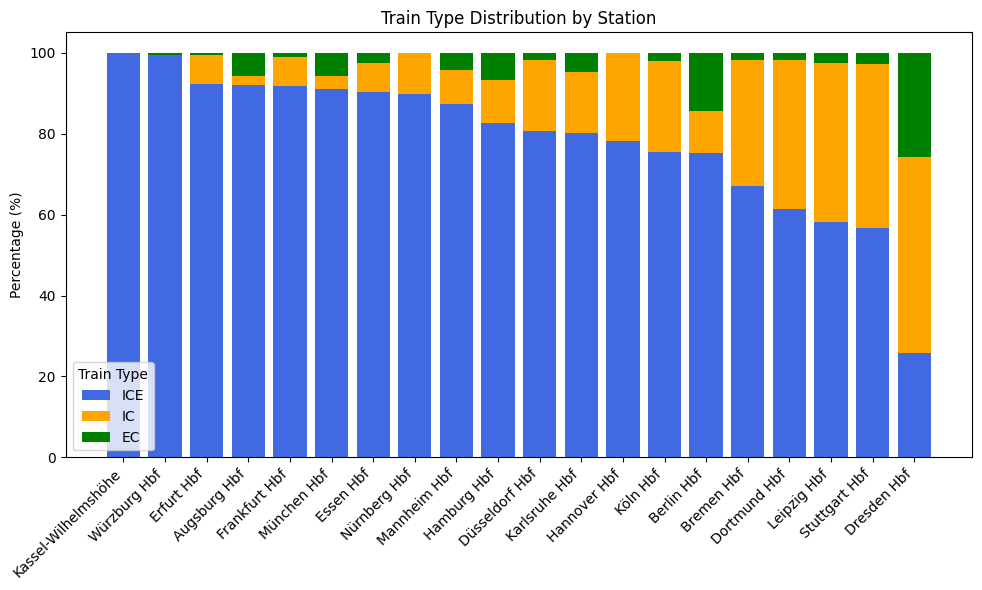

In [56]:
# Pick top N stations for visibility (e.g. top 10 by total_trains or specialization)
plot_df = pivot_df.sort_values(by="specialization_index", ascending=False)

# Plotting
fig, ax = plt.subplots(figsize=(10, 6))

# Stacked bar parts
ax.bar(plot_df['station'], plot_df['ICE_percent'], label='ICE', color='royalblue')
ax.bar(plot_df['station'], plot_df['IC_percent'], bottom=plot_df['ICE_percent'], label='IC', color='orange')
ax.bar(plot_df['station'], plot_df['EC_percent'], 
       bottom=plot_df['ICE_percent'] + plot_df['IC_percent'], label='EC', color='green')

# Labels and styling
ax.set_ylabel("Percentage (%)")
ax.set_title("Train Type Distribution by Station")
ax.set_xticklabels(plot_df['station'], rotation=45, ha='right')
ax.legend(title="Train Type")
plt.tight_layout()
plt.show()


  The analysis of train type specialization by station confirms the hypothesis that major hubs show
  strong ICE dominance, while regional stations display more diverse service mixes.
  Kassel-Wilhelmshöhe exhibits extreme specialization with 100% ICE service, operating exclusively as
   a long-distance high-speed hub with no regional traffic. Major metropolitan stations including
  Würzburg Hbf, Erfurt Hbf, and Frankfurt Hbf also demonstrate strong ICE dominance, with each
  operating over 90% high-speed express services. This concentration of ICE traffic at primary hubs
  reflects their role as long-distance travel consolidation points and indicates significant
  infrastructure investment and scheduling prioritization for express routes. In contrast, Dresden
  Hbf presents a notably different profile, with IC trains forming the largest share at 48.4%,
  indicating a greater emphasis on intercity and regional connections rather than high-speed express
  services. This divergence suggests that Dresden, despite its geographic importance, either serves
  primarily as a regional hub or operates under different service strategies than the major western
  metropolitan centers. The observed specialization patterns underscore the strategic roles of
  different stations within the network: stations serving primarily long-distance corridors maintain
  high ICE percentages, while those with greater regional connectivity requirements show more
  balanced or IC-focused distributions. This specialization reflects both infrastructure capabilities
   and operational priorities, with major hubs designed and operated to maximize high-speed express
  services while regional stations accommodate a broader spectrum of service types.

## RQ4: Most Important Rail Corridors
  This research question identifies the most critical train corridors within the German railway
  network through two complementary analytical approaches. First, we analyze
  origin-to-final-destination routes originating from major stations to identify the most frequently
  traveled long-distance paths and understand primary passenger flow patterns across the country.
  Second, we examine bidirectional traffic between consecutive station pairs to reveal the physical
  backbone of the network and quantify any imbalances in traffic flow direction. These two
  perspectives together provide comprehensive insight into which corridors are operationally most
  important: the first approach captures strategic long-distance connections that define inter-city
  travel demand, while the second reveals the heavily-used network segments that require robust
  infrastructure and reliable operations. Our hypothesis is that major metropolitan centers serve as
  origin and destination hubs, creating pronounced directional imbalances, while geographically
  central corridors such as those connecting München, Frankfurt, and Stuttgart will show more
  balanced bidirectional traffic reflecting their role as consolidated transfer points. Understanding
   corridor importance and traffic patterns is essential for identifying potential network
  bottlenecks and prioritizing operational investments.

### Origin-to-Final-Destination Routes

In [80]:
OBSERVED_STATIONS = [
    'Augsburg Hbf', 'Berlin Hbf', 'Bremen Hbf', 'Dortmund Hbf', 'Dresden Hbf',
    'Düsseldorf Hbf', 'Erfurt Hbf', 'Essen Hbf', 'Frankfurt Hbf', 'Hamburg Hbf',
    'Hannover Hbf', 'Karlsruhe Hbf', 'Köln Hbf', 'Leipzig Hbf', 'Mannheim Hbf',
    'München Hbf', 'Nürnberg Hbf', 'Stuttgart Hbf', 'Würzburg Hbf', 'Kassel-Wilhelmshöhe'
]

In [82]:
match = {
    "$match": {
        "departure.path": {"$exists": True, "$ne": ""},
        "station.name": {"$in": OBSERVED_STATIONS}
    }
}
project1 = {
    "$project": {
        "origin": "$station.name",
        "path": { "$split": ["$departure.path", "|"]}
    }
}
project2 = {
    "$project": {
        "origin": 1,
        "destination": { "$arrayElemAt": ["$path", -1]}
    }
}
group = {
    "$group": {
        "_id": {"origin": "$origin", "destination": "$destination"},
        "count": {"$sum": 1}
    }
}
project3 = {
    "$project": {
        "_id": 0,
        "origin": "$_id.origin",
        "destination": "$_id.destination",
        "count": 1
    }
}
sort = {
    "$sort": {"count": -1}
}
limit = {
    "$limit": 20
}

In [90]:
pipeline = [match, project1, project2, group, project3, sort, limit]

result = list(collection.aggregate(pipeline))
df_corridors = pd.DataFrame(result)
#df_corridors

/var/folders/5h/7hhdw_3j1bz_15_wtp0jmb_80000gn/T/ipykernel_40900/1567359298.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


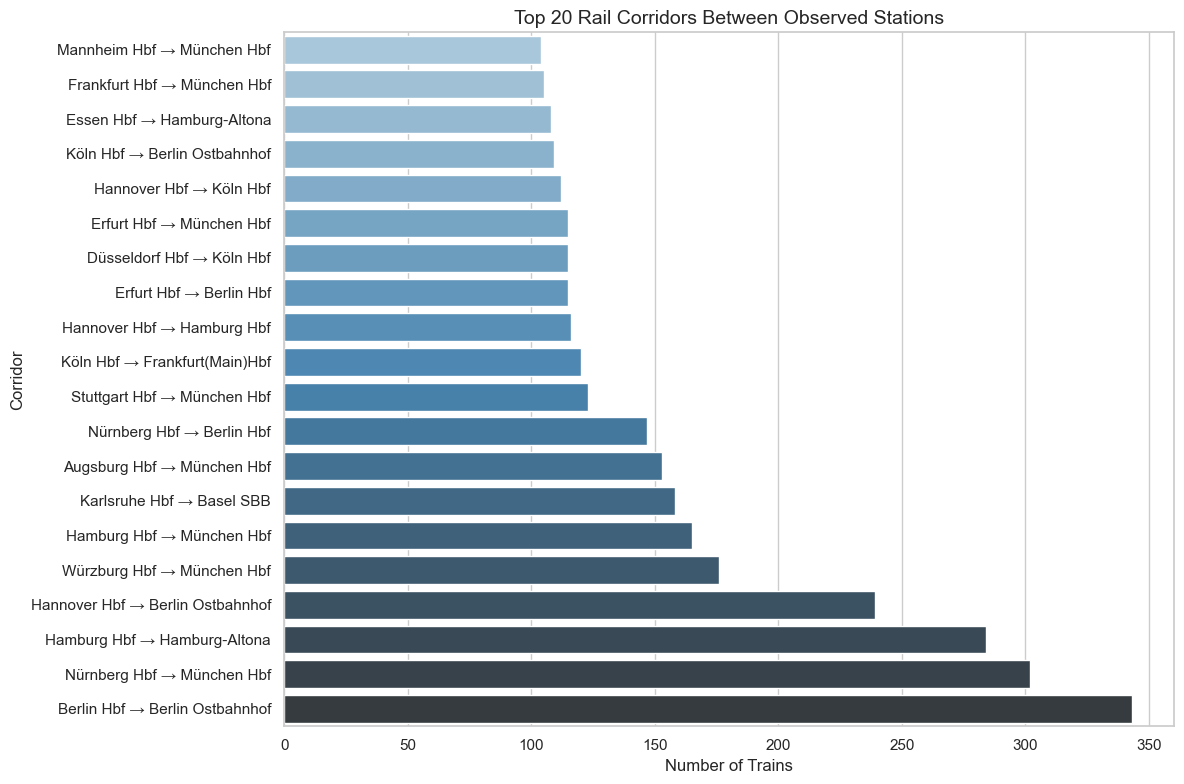

In [90]:
# new column for visualization
df_corridors["corridor"] = df_corridors["origin"] + " → " + df_corridors["destination"]

# Sort by count ascending for barh orientation
df_corridors = df_corridors.sort_values(by="count", ascending=True)

# Plot
plt.figure(figsize=(12, 8))
sns.barplot(
    data=df_corridors,
    x="count",
    y="corridor",
    palette="Blues_d"
)
plt.title("Top 20 Rail Corridors Between Observed Stations", fontsize=14)
plt.xlabel("Number of Trains")
plt.ylabel("Corridor")
plt.tight_layout()
plt.show()

The initial analysis focuses on the most frequent origin-to-final-destination routes originating from major stations. A notable pattern emerges: the most frequent routes are short-distance connections, such as Berlin Hbf to Berlin Ostbahnhof (343 journeys) and Hamburg Hbf to  Hamburg-Altona (284 journeys). Given that data was collected late in the evening (around 22:00), this suggests these are not standalone short trips, but rather the final leg of longer journeys where trains are approaching their ultimate destination.

Beyond these end-of-line segments, the analysis highlights that the most significant long-distance corridors are directed towards München Hbf, with routes from Nürnberg, Würzburg, and Frankfurt all appearing in the top results. Overall, the key hubs identified in these primary travel patterns are Berlin, München, Hamburg, Basel, and Köln, underscoring their central role in the national network.

### Bidirectional Corridor Analysis and Imbalance

While the previous analysis identified primary origin-to-final-destination routes, this section delves deeper into the actual segments of the network by analyzing consecutive station pairs. We aim to identify the most frequently served corridors, considering traffic in both directions, and to quantify any imbalance in traffic flow between the two directions. This reveals the true backbone of the rail network and highlights critical segments for operational planning.

In [80]:
match1 = {
    "$match": {
        "departure.path": {"$exists": True}
    }
}
project1 = {
    "$project": {
        "origin": "$station.name",
        "destination": {
            "$arrayElemAt": [
                {"$split": ["$departure.path", "|"]},
                -1
            ]
        }
    }
}
project2 = {
    "$project": {
        "origin": 1,
        "destination": 1,
        "corridor": {
            "$cond": [
                { "$lt": ["$origin", "$destination"] },
                { "$concat": ["$origin", " - ", "$destination"] },
                { "$concat": ["$destination", " - ", "$origin"] }
            ]
        },
        "direction": {
            "$cond": [
                { "$lt": ["$origin", "$destination"] },
                "AB",
                "BA"
            ]
        }
    }
}
group = {
    "$group": {
        "_id": {
            "corridor": "$corridor"
        },
        "count": {"$sum": 1},
        "count_AB": {
            "$sum": {
                "$cond": [{ "$eq": ["$direction", "AB"] }, 1, 0]
            }
        },
        "count_BA": {
            "$sum": {
                "$cond": [{ "$eq": ["$direction", "BA"] }, 1, 0]
            }
        }
    }
}
project3 = {
    "$project": {
        "_id": 0,
        "corridor": "$_id",
        "A_to_B": "$count_AB",
        "B_to_A": "$count_BA",
        "total_trains": "$count",
        "min_traffic": {"$min": ["$count_AB", "$count_BA"]},
        "imbalance_ratio": {
            "$round": [
                {
                    "$divide": [
                        { "$abs": { "$subtract": ["$count_AB", "$count_BA"] } },
                        { "$add": ["$count_AB", "$count_BA"] }
                    ]
                }, 2
            ]
        }
    }
}
match2 = {
    "$match": {
        "A_to_B": { "$gte": 10 },
        "B_to_A": { "$gte": 10 }
    }
}
sort1 = {
    "$sort": {
        "imbalance_ratio": 1,
        "total_trains": -1
    }
}
sort2 = {
    "$sort": {
        "imbalance_ratio": -1,
        "total_trains": -1
    }
}
limit = {
    "$limit": 20
}
project4 = {
    "$project": {
        "min_traffic": 0
    }
}

In [85]:
pipeline = [match1, project1, project2, group, project3, sort1, project4]
result = list(collection.aggregate(pipeline))
df_all_corridors = pd.DataFrame(result)
display(df_all_corridors.head(10).style.set_caption("Top 10 Most Balanced Origin-Destination Corridors"))


,corridor,A_to_B,B_to_A,total_trains,imbalance_ratio
0,{'corridor': 'Karlsruhe Hbf - Leipzig Hbf'},19,19,38,0.000000
1,{'corridor': 'Erfurt Hbf - Stuttgart Hbf'},1,1,2,0.000000
2,{'corridor': 'Hamburg Hbf - Karlsruhe Hbf'},28,30,58,0.030000
3,{'corridor': 'Düsseldorf Hbf - Essen Hbf'},49,53,102,0.040000
4,{'corridor': 'Dortmund Hbf - Dresden Hbf'},28,26,54,0.040000
5,{'corridor': 'Karlsruhe Hbf - München Hbf'},11,12,23,0.040000
6,{'corridor': 'Düsseldorf Hbf - Stuttgart Hbf'},9,8,17,0.060000
7,{'corridor': 'Dortmund Hbf - München Hbf'},42,48,90,0.070000
8,{'corridor': 'Berlin Hbf - Dortmund Hbf'},6,5,11,0.090000
9,{'corridor': 'Dortmund Hbf - Köln Hbf'},51,62,113,0.100000


In [86]:
pipeline = [match1, project1, project2, group, project3, sort2, project4]
result = list(collection.aggregate(pipeline))
df_all_corridors = pd.DataFrame(result)
display(df_all_corridors.head(10).style.set_caption("Lowest 10 Most Balanced Origin-Destination Corridors"))

,corridor,A_to_B,B_to_A,total_trains,imbalance_ratio
0,{'corridor': 'Berlin Hbf - Berlin Ostbahnhof'},343,0,343,1.000000
1,{'corridor': 'Hamburg Hbf - Hamburg-Altona'},284,0,284,1.000000
2,{'corridor': 'Berlin Ostbahnhof - Hannover Hbf'},0,239,239,1.000000
3,{'corridor': 'München Hbf - Würzburg Hbf'},0,176,176,1.000000
4,{'corridor': 'Basel SBB - Karlsruhe Hbf'},0,158,158,1.000000
5,{'corridor': 'Augsburg Hbf - München Hbf'},153,0,153,1.000000
6,{'corridor': 'Berlin Hbf - Nürnberg Hbf'},0,147,147,1.000000
7,{'corridor': 'Frankfurt(Main)Hbf - Köln Hbf'},0,120,120,1.000000
8,{'corridor': 'Berlin Hbf - Erfurt Hbf'},0,115,115,1.000000
9,{'corridor': 'Berlin Ostbahnhof - Köln Hbf'},0,109,109,1.000000


The analysis of bidirectional traffic reveals two distinct types of corridors. On one hand, the most balanced routes, such as Karlsruhe Hbf <-> Leipzig Hbf and Erfurt Hbf <-> Stuttgart Hbf, exhibit nearly perfect symmetrical traffic with an imbalance ratio of 0.0. These represent stable, reciprocal connections with consistent service demand in both directions.

On the other hand, the most imbalanced corridors all show a complete imbalance ratio of 1.0, meaning traffic between the journey's origin and its final destination was observed in only one direction in our dataset. This is prominent in routes like Berlin Hbf -> Berlin Ostbahnhof and Hamburg Hbf -> Hamburg-Altona. This unidirectional flow is particularly insightful: it suggests that these are often the final legs of longer journeys, with trains terminating at these stations (e.g., Ostbahnhof or Altona) rather than originating a return journey from them. This highlights both the stable, bidirectional backbones and the asymmetric, operational realities of the rail network.

### Summary

 The two-part analysis of rail corridors reveals both the strategic long-distance connectivity
  patterns and the operational backbone of the German railway network. The
  origin-to-final-destination analysis identifies München Hbf, Berlin, Hamburg, Basel, and Köln as
  the dominant hub destinations, with significant traffic flows from Nürnberg, Würzburg, and
  Frankfurt converging on München. The prominence of short-distance terminal segments (Berlin
  Ostbahnhof, Hamburg-Altona) reflects the data collection timing around 22:00, capturing the final
  legs of longer journeys rather than standalone trips. This pattern underscores the hub-dependent
  structure of long-distance travel, where passengers converge on major metropolitan centers through
  inter-city express connections.

  The bidirectional corridor analysis reveals a strong contrast between two corridor types that
  characterize the network. Balanced corridors such as Karlsruhe Hbf to Leipzig Hbf and Erfurt Hbf to
   Stuttgart Hbf exhibit nearly perfect symmetrical traffic with imbalance ratios of 0.0,
  representing stable reciprocal connections with consistent demand in both directions. These
  corridors form the true backbone of the network, supporting reliable bidirectional services.
  Conversely, the most imbalanced corridors show complete unidirectionality (imbalance ratio of 1.0),
   dominated by terminal flows such as Berlin Hbf to Berlin Ostbahnhof and Hamburg Hbf to
  Hamburg-Altona. Together, these findings demonstrate that the German railway network comprises both
   stable bidirectional trunk lines that form the operational foundation and asymmetric end-of-line
  segments that reflect the hub-centric nature of long-distance travel. The combination of
  concentrated long-distance flows toward major metropolitan centers and unidirectional terminal
  segments illustrates how the network is designed to consolidate traffic through major hubs rather
  than support distributed regional connectivity patterns.

## RQ5: Peak Hour Performance Analysis
  This research question investigates whether train delays increase during peak hours, which would
  indicate network congestion and operational bottlenecks. By examining temporal delay patterns
  throughout the day, we can identify if and when the railway network experiences the most strain and
   operational stress. Peak hours are defined as 6:00 to 9:00 AM and 4:00 to 7:00 PM, capturing the
  traditional morning and evening commute periods when transportation demand is typically highest.
  Our hypothesis is that average delays will be measurably higher during these peak periods compared
  to off-peak hours, with the evening peak showing more pronounced delay increases due to the
  accumulation of operational disruptions throughout the day. Additionally, we expect to observe high
   variability in delay patterns during peak hours, reflecting the unpredictability that accompanies
  network congestion. This analysis examines average delays, delay variability, and train volumes
  across all hours to determine whether temporal patterns in delay performance align with traffic
  demand and to identify the times when the network operates under the most critical conditions.

In [107]:
match = {
    "$match": {
        "hour": {"$ne": None},
        "departure.delay_minutes": {"$ne": None}
    }
}
group = {
    "$group": {
        "_id": "$hour",
        "train_count": {"$sum": 1},
        "avg_delay": {"$avg": "$departure.delay_minutes"},
        "delay_std_dev": {"$stdDevSamp": "$departure.delay_minutes"}
    }
}
sort = {
    "$sort": {
        "_id": 1
    }
}
project = {
    "$project": {
        "_id": 0,
        "hour": "$_id",
        "train_count": 1,
        "avg_delay_minutes": "$avg_delay",
        "delay_std_dev": "$delay_std_dev"
    }
}

In [115]:
pipeline = [match, group, sort, project]

result = list(collection.aggregate(pipeline))
df_corridors = pd.DataFrame(result)

df_corridors = df_corridors.round(1)
#df_corridors

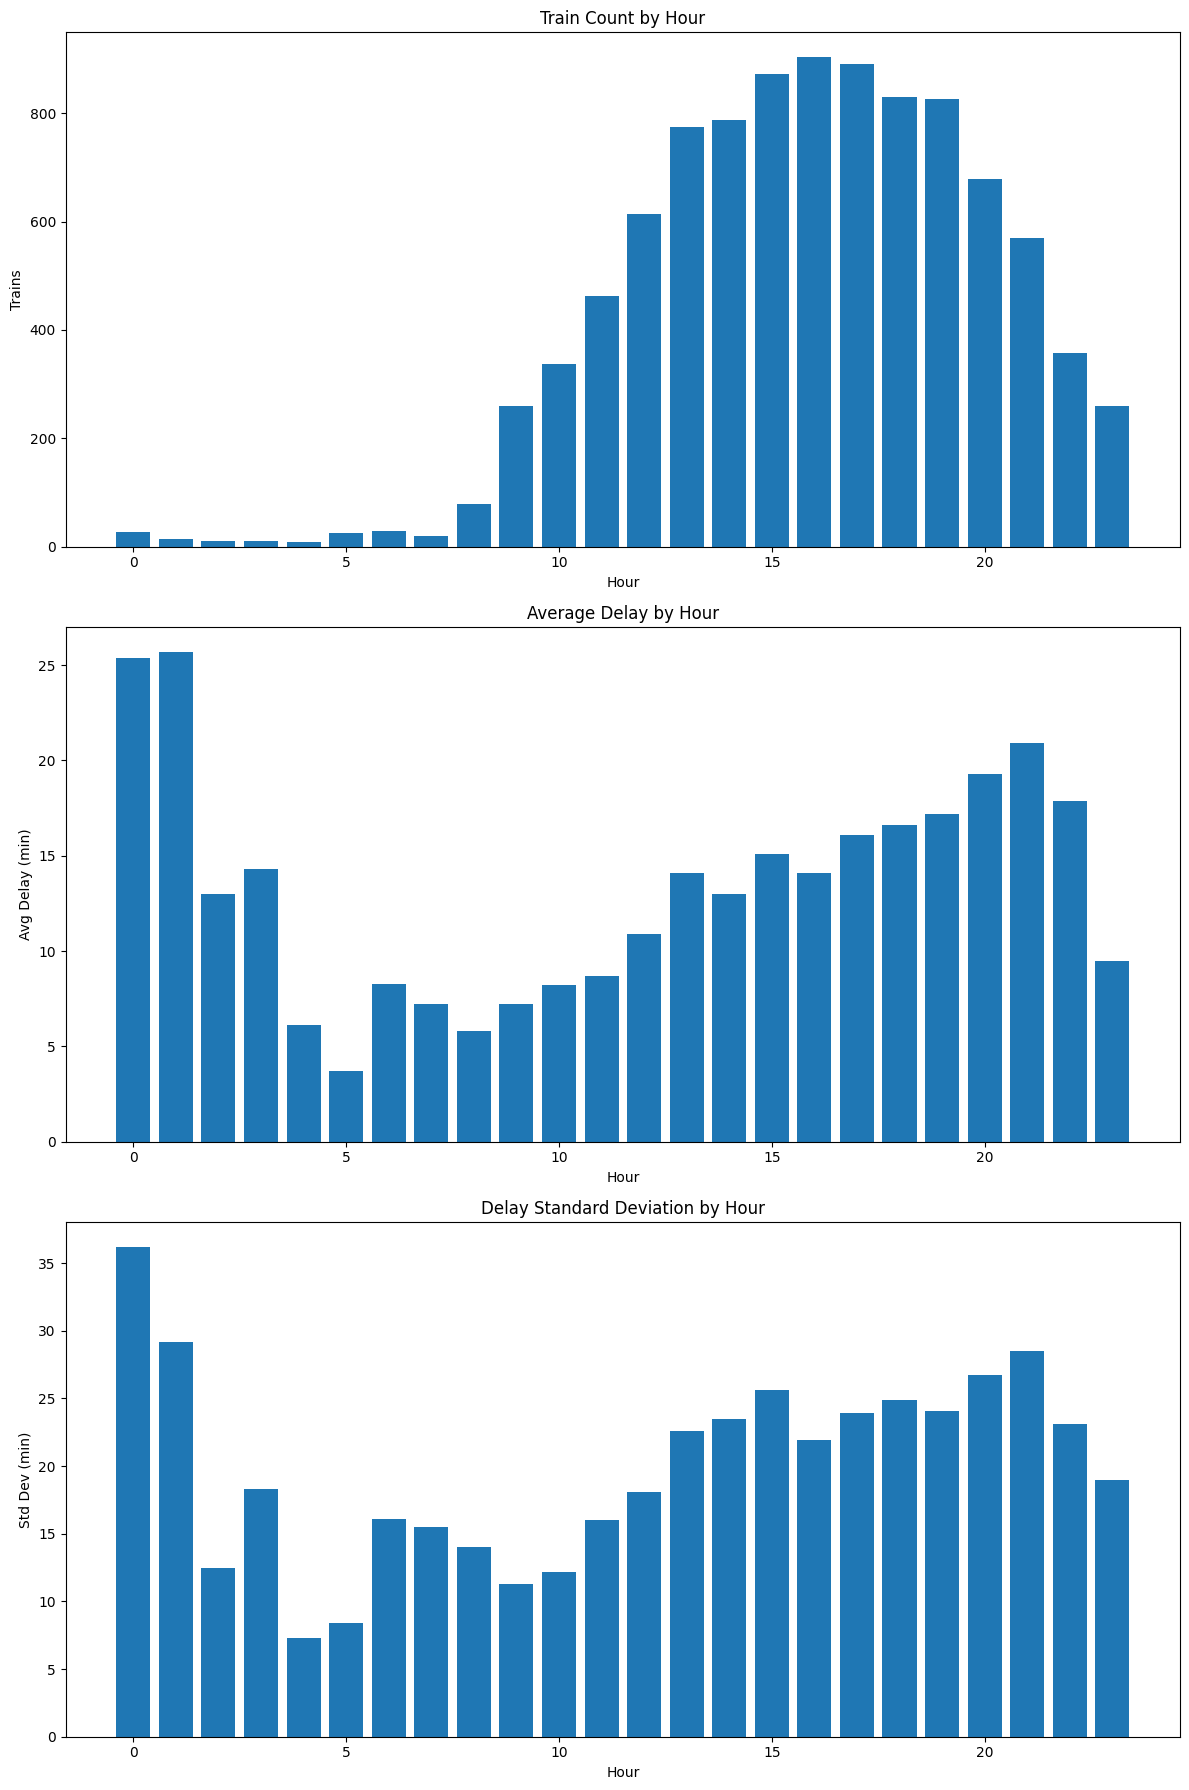

In [114]:
fig, ax = plt.subplots(3, 1, figsize=(12, 18))

# Train count
ax[0].bar(df_corridors['hour'], df_corridors['train_count'])
ax[0].set_title("Train Count by Hour")
ax[0].set_xlabel("Hour")
ax[0].set_ylabel("Trains")

# Avg delay
ax[1].bar(df_corridors['hour'], df_corridors['avg_delay_minutes'])
ax[1].set_title("Average Delay by Hour")
ax[1].set_xlabel("Hour")
ax[1].set_ylabel("Avg Delay (min)")

# Delay Std Dev
ax[2].bar(df_corridors['hour'], df_corridors['delay_std_dev'])
ax[2].set_title("Delay Standard Deviation by Hour")
ax[2].set_xlabel("Hour")
ax[2].set_ylabel("Std Dev (min)")

plt.tight_layout()
plt.show()


  The analysis of hourly performance provides clear evidence that train delays are strongly
  correlated with network congestion, particularly during evening peak hours. The hypothesis that
  delays increase during peak hours is confirmed, with the most significant findings occurring during
   and after the evening peak (16:00 to 19:00). The highest train volumes and the highest average
  delays are concentrated in the evening peak hours, with average delays climbing steadily to reach
  17.2 minutes around 19:00 (7 PM). This represents a substantial increase over typical off-peak
  delay levels, demonstrating that the evening rush period creates measurable operational stress on
  the network.

  A critical finding is the cascading effect observed in the late-evening hours (20:00 onwards).
  Despite a sharp drop in train volume after 20:00 (8 PM), average delays remain exceptionally high,
  even peaking at 20.9 minutes at 21:00 (9 PM). This counterintuitive pattern indicates that delays
  accumulated during the evening peak are not quickly resolved and continue to impact the fewer
  services operating later in the day. The high delay standard deviation during these hours further
  reveals that delays are not only elevated but also unpredictable, with some trains running severely
   late while others approach scheduled times. The morning peak (6:00 to 9:00 AM) shows elevated
  train traffic and moderate delay increases, but the impact on average delays is considerably less
  pronounced than the evening period, suggesting that morning operations, while busy, do not
  accumulate delays in the same manner as evening operations. These findings support the hypothesis
  that peak hours drive network strain and extend the analysis to show that the evening peak and its
  cascading effects represent the most critical operational period, requiring focused management
  attention and infrastructure consideration for maintaining service reliability.

# Conclusions
  This project successfully leveraged the Deutsche Bahn API and MongoDB to conduct a comprehensive,
  multi-dimensional analysis of the German railway network's structure, connectivity, and operational
   performance. The investigation across five interconnected research questions reveals a complex,
  hierarchically organized system operating under significant temporal stress.

  The network exhibits a pronounced hub-dependent structure, confirmed by RQ2's finding that
  Frankfurt Hbf, München Hbf, and Stuttgart Hbf dominate with 203, 187, and 186 unique connections
  respectively. This hierarchy extends to service specialization (RQ3), where major metropolitan
  centers show extreme ICE dominance (often exceeding 90%), reflecting their role as long-distance
  consolidation points. The corridor analysis (RQ4) further reinforces this structure, demonstrating
  that long-distance travel flows concentrate toward major hubs while bidirectional trunk lines
  (Karlsruhe to Leipzig, Erfurt to Stuttgart) form the operational backbone. This hub-centric design
  efficiently consolidates national traffic but creates potential single-point-of-failure
  vulnerabilities.

  Operational performance, however, does not correlate linearly with hub size or connectivity. RQ1's
  findings challenge the conventional assumption that major hubs operate most efficiently: Mannheim
  Hbf, a mid-tier hub, achieves the best delay recovery at minus 1.0 minutes, while major hubs
  Frankfurt and Hamburg add delays on average. This divergence suggests that factors beyond
  infrastructure investment—such as scheduled turnaround buffers, platform utilization efficiency,
  and traffic composition—significantly influence operational outcomes. The worst-performing station,
   Erfurt Hbf, demonstrates that even moderately connected hubs can struggle with delay management
  when operational design is suboptimal.

  Temporal analysis (RQ5) identifies the evening peak (16:00 to 19:00) as the network's most critical
   operational period. Average delays reach 17.2 minutes at 19:00, and despite declining train
  volumes after 20:00, delays persist at elevated levels (peaking at 20.9 minutes at 21:00),
  indicating a cascading effect where congestion-induced disruptions propagate through the late-night
   schedule. This cascading phenomenon suggests that peak-period capacity constraints create
  operational debts that cannot be quickly resolved, accumulating impact across subsequent services.

  Together, these findings establish that the German railway network is a hub-dependent system
  operating near capacity during evening peak hours. Optimizing delay recovery requires
  station-specific operational design rather than assuming size guarantees efficiency. The cascading
  delay effects observed during evening peaks indicate that sustainable reliability requires either
  expanded capacity or demand management strategies. Future improvements should prioritize evening
  peak efficiency and examine delay propagation to prevent cascading failures.

# Learnings
  This project provided several valuable lessons about working with external APIs, data engineering,
  and documentation practices that extend beyond the technical findings themselves.

  **API Limitations and Hidden Constraints:** Working with the Deutsche Bahn API revealed that API
  documentation does not always make explicit the operational constraints that fundamentally affect
  data collection strategy. Discovering that the API retains historical data for only approximately
  12 hours required a complete rethinking of the collection methodology. The initial plan to retrieve
   a week of historical data in bulk became infeasible, necessitating a pivot to multiple daily
  collections at strategic times (10:00 PM) to capture the maximum temporal window of available data.
   This experience underscores the importance of early API exploration and testing before committing
  to a full data collection pipeline. Understanding API limitations before scaling operations would
  have prevented the wasted effort and design revisions.

  **The Hidden Cost of Small Typos:** Debugging logic errors in data pipelines is substantially more
  challenging than in traditional software development because errors often manifest as silent data
  quality issues rather than runtime exceptions. Small typos in field names, function parameters, or
  aggregation pipeline expressions consumed disproportionate debugging time, sometimes requiring
  hours to trace back to single-character errors. This experience highlighted the value of careful
  code review, comprehensive logging, and unit testing for data processing functions. Investing in
  preventive measures such as automated schema validation and type checking at data boundaries would
  have caught such errors immediately rather than allowing them to propagate through the entire
  pipeline.

  **Documentation and Formatting as Non-Trivial Effort:** Creating professional-quality technical
  documentation proved surprisingly time-intensive. Beyond simply writing clear explanations,
  formatting requirements, maintaining consistent structure across chapters, managing code
  presentation, and ensuring visual coherence demanded substantial effort. Schema diagrams, data
  quality tables, and results visualizations each required design decisions and refinement. This
  experience demonstrates that technical projects should allocate significant time and resources to
  documentation as a first-class deliverable rather than treating it as an afterthought. Quality
  documentation enhances reproducibility, enables future analysis, and makes findings more accessible
   to stakeholders.

  **Implications for Future Work:** These learnings suggest several best practices for future data
  engineering projects: thoroughly test and document any external API before committing to
  large-scale collection; implement early validation and error detection mechanisms to catch small
  issues before they cascade; and plan documentation effort as a core project component rather than a
   final phase afterthought. The combination of these factors significantly impacts both project
  timeline and final deliverable quality.

